# Studio Proyek 3 - Fine-Tuning Transformer Pretrained untuk NLP

**Mata Kuliah:** Pembelajaran Mendalam (IF25-40401) - Teknik Informatika ITERA
**Kelas:** Deep Learning RA (IF25-40401)

**Tugas:** Klasifikasi sentimen teks Bahasa Indonesia (negatif / netral / positif) pada dataset **SmSA (IndoNLU)**.

| No | Nama Lengkap | NIM |
|:-:|---|---|
| 1 | Muhammad Fadhilah Akbar | 123140003 |
| 2 | Muhammad Fajri Firdaus | 123140050 |

**Kelompok 15**
Nama berkas PDF sesuai spesifikasi: `STUDIO3_Kelompok15_MuhammadFadhilahAkbar_MuhammadFajriFirdaus.pdf`

---

---

**Tautan tugas**

| Item | Tautan |
|---|---|
| Notebook Colab (siap dijalankan) | https://colab.research.google.com/drive/1aUzn6Cqp_FKpQx5ZEoFjkkCE3nSKan6R?usp=sharing |
| Repositori GitHub | https://github.com/123140003-MuhammadFadhilahAkbar/Studio-Proyek-3_NLP |


## 0. Cara Pakai Notebook

1. **Aktifkan GPU.** Colab: *Runtime → Change runtime type → T4 GPU*. Kaggle: *Settings → Accelerator → GPU T4*, dan nyalakan *Internet*.
2. **Uji jalan sekali (disarankan).** Di bagian 2, set `UJI_JALAN = True`, lalu *Run all*. Mode uji **tidak** diblokir oleh gate Rancangan. Notebook memakai subset kecil, 1 seed, 1 epoch, dan menulis ke berkas `*_uji_*` sehingga berkas hasil resmi tidak terkontaminasi. Kalau tidak ada error, set kembali `UJI_JALAN = False`.
3. **Konfirmasi rancangan.** Baca dan sesuaikan isi **Rancangan** (bagian 3), lalu ubah `RANCANGAN_DIKONFIRMASI = True`. Notebook **menolak mode `"penuh"`** selama rancangan belum dikonfirmasi atau masih ada isian yang kosong.
4. Jalankan semua sel secara berurutan (*Run all*). Matriks bawaan berisi **3 backbone × 3 strategi × 3 seed = 27 run** (≈ 1–3 menit/run di T4 dengan 6.000 data latih).
5. **Tahan putus sesi:** setiap run langsung disimpan ke CSV. Di **Colab**, folder hasil otomatis ditempatkan di **Google Drive** (`MyDrive/Hasil_Studio3/hasil_studio3`; setujui izin akses Drive saat sel bagian 2 meminta), sehingga hasil tetap ada walau runtime di-reset. Kalau sesi terputus, jalankan ulang semua sel dan run yang sudah selesai akan **dilewati otomatis**. Di Kaggle, hasil ada di `/kaggle/working`.
6. **Membagi kerja antar-anggota:** setiap anggota mengisi `JALANKAN_BACKBONE` (bagian 2) dengan backbone bagiannya, lalu CSV hasilnya digabung di bagian 8.
   Konfigurasi lain **harus identik** (dicek otomatis lewat kode konfigurasi).

### Peta notebook ↔ Lembar Soal & Spesifikasi

| Bagian notebook | Yang dijawab (Lembar Soal / Spesifikasi) |
|---|---|
| 1. Setup Lingkungan | Spesifikasi "Hal teknis": platform Colab/Kaggle + pustaka wajib (`transformers`, `scikit-learn`) |
| 2. Konfigurasi | Skema 1c / C.1: kunci `max_length`, batch size, epoch, ≥ 3 seed yang sama; ukuran subset (Slide 10) |
| 3. Rancangan | Skema 1 / C.1: matriks backbone × strategi, hipotesis H1–H3, alasan, variabel terkendali, kriteria Q1–Q3 |
| 4. Data | Slide 10: latih 3.000–6.000, validasi ≥ 500 **hanya untuk memilih epoch**, uji = **seluruh 500 uji resmi**, disentuh sekali per run |
| 4.3 Baseline TF-IDF & tebakan acak | Slide 11 "Pembanding yang sah" |
| 5. Model | Skema 3 / C.3: head replacement, full FT, partial freezing, linear probing (kode freezing eksplisit) |
| 6–7. Pelatihan & Matriks | Skema 2 + 3 / C.2 + C.3: 3 backbone × 3 strategi × 3 seed, protokol identik |
| 8. Gabung antar-anggota | Penunjang pembagian kerja kelompok |
| 9. Benchmark inferensi | Waktu inferensi (ms/kalimat) hanya dibandingkan dalam satu sesi |
| 10. Rekap agregat | Rata-rata ± simpangan baku antar-seed → `rekap_agregat_<dataset>_<kode>.csv` |
| 11–12. Visualisasi & hipotesis | Pengujian H1–H3 + tabel bukti Q1–Q3 |
| 13. Analisis & kesimpulan | Slide 9: **3 Pertanyaan Riset Wajib (Q1–Q3)** |
| 14. Kepatuhan & berkas | Kriteria "Selesai" Skema 1–3, cek kewajaran skor (Slide 11), deliverables (Slide 14) |

## 1. Setup Lingkungan

*Klausul "Hal-hal Teknis": platform Google Colab / Kaggle Notebook (GPU gratis) dan pustaka wajib HuggingFace `transformers` + `scikit-learn`.*

Pustaka wajib: **HuggingFace `transformers`** dan **`scikit-learn`**. Dataset SmSA diunduh langsung dari repositori resmi IndoNLU, jadi pustaka `datasets` tidak diperlukan (pustaka itu hanya dipakai kalau memakai IMDb).

In [1]:
# Colab/Kaggle umumnya sudah memiliki paket ini; perintah di bawah hanya memastikan versinya memadai.
%pip install -q "transformers>=4.40" scikit-learn pandas matplotlib

In [2]:
import os
# Wajib di-set SEBELUM torch dipakai agar operasi cuBLAS deterministik (reproduksibilitas).
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import csv, gc, hashlib, json, math, platform, random, time, urllib.request, warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Dataset

import transformers
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup, set_seed)
import sklearn
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=UserWarning)
transformers.logging.set_verbosity_error()

# Reproduksibilitas: algoritma deterministik (warn_only agar op tanpa versi deterministik tidak error)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"          # mixed precision fp16 di GPU -> lebih cepat & hemat memori
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"

print(f"Python       : {platform.python_version()}")
print(f"torch        : {torch.__version__}")
print(f"transformers : {transformers.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"Perangkat    : {DEVICE} ({GPU_NAME}) | AMP fp16: {USE_AMP}")
if DEVICE.type != "cuda":
    print("\n⚠️  GPU tidak terdeteksi! Mode 'penuh' akan sangat lambat di CPU. Aktifkan GPU T4 dulu.")

Python       : 3.13.16
torch        : 2.14.1+cu130
transformers : 5.22.1
scikit-learn : 1.6.1
Perangkat    : cuda (Tesla T4) | AMP fp16: True


## 2. Konfigurasi Eksperimen (Variabel Terkunci)

*Skema 1c / C.1 — "Kunci variabel: max_length, batch size, jumlah epoch, dan minimal 3 seed acak yang SAMA di semua run". Semua variabel terkunci ditulis eksplisit di sel kode berikut.*

| Variabel | Nilai | Keterangan |
|---|---|---|
| `MAX_LENGTH` | 128 token | Mencakup ≥ 99% kalimat SmSA (dicek di bagian 5.1) |
| `BATCH_SIZE` | 32 | Muat di memori T4 untuk model base dengan fp16 |
| `EPOCHS` | 3 | Jumlah epoch maksimum; **epoch terbaik dipilih dengan F1 makro validasi** (Slide 10) |
| `SEEDS` | 42, 123, 2024 | Seed yang **sama** untuk semua kombinasi |
| `TRAIN_SUBSET` | 6.000 | Subset latih terstratifikasi (Slide 10: min 3.000, maks 6.000), `DATA_SEED` = 42 |
| Validasi | seluruh validasi resmi hasil pembersihan (≥ 500) | **Hanya** untuk memilih epoch terbaik |
| Uji | seluruh **500** kalimat uji resmi | Disentuh **sekali** per run (setelah epoch terbaik dipilih) |
| Optimizer | AdamW, weight decay 0,01 | Warmup linear 10%, lalu decay linear, gradient clipping 1,0 |
| Learning rate | full 2e-5 · partial 3e-5 · probing 5e-3 | Disesuaikan per strategi, di dalam rentang spesifikasi |
| `MODE` / `UJI_JALAN` | `"penuh"` / `False` | `UJI_JALAN = True` = uji jalan 1 seed, 1 epoch, subset kecil (berkas `*_uji_*`) |

**Kode konfigurasi** (`KODE`) adalah hash dari semua variabel terkunci. Jika satu nilai saja berubah, kodenya berubah, sehingga file hasilnya terpisah dan tidak tercampur.

In [3]:
# ============================ KONFIGURASI ============================
# ---- SAKLAR UJI JALAN (jalankan notebook SEKALI dari atas ke bawah untuk memastikan tidak ada error) ----
UJI_JALAN = False         # True = subset kecil, 1 seed, 1 epoch. Hasil disimpan ke berkas *_uji_* (terpisah dari berkas resmi).
                          # Kalau uji jalan sudah terbukti lancar, ubah kembali ke False.
RANCANGAN_DIKONFIRMASI = True    # wajib True sebelum MODE "penuh" (bagian 3); sudah ditinjau kelompok

DATASET   = "smsa"
LABELS    = ["negative", "neutral", "positive"]
LABEL2ID  = {lab: i for i, lab in enumerate(LABELS)}
ID2LABEL  = {i: lab for lab, i in LABEL2ID.items()}
NUM_LABELS = len(LABELS)

# ---- Backbone (Soal 2). Model English-only TIDAK dipakai di SmSA. ----
BACKBONES = {
    "mbert": {
        "hf": "bert-base-multilingual-cased",
        "nama": "mBERT",
        "peran": "Baseline utama (BERT multibahasa, 104 bahasa)",
    },
    "distilmbert": {
        "hf": "distilbert-base-multilingual-cased",
        "nama": "DistilmBERT",
        "peran": "Versi distilasi mBERT (6 lapis) — untuk melihat efisiensi",
    },
    "indobert": {
        "hf": "indobenchmark/indobert-base-p1",
        "nama": "IndoBERT",
        "peran": "Monolingual Indonesia (pretraining Indo4B)",
    },
}
PAKAI_XLMR = False        # Opsional (nilai plus): True -> tambah XLM-R base (+9 run, ~2x lebih lama per run)
if PAKAI_XLMR:
    BACKBONES["xlmr"] = {
        "hf": "xlm-roberta-base",
        "nama": "XLM-R",
        "peran": "Multibahasa bergaya RoBERTa (kosakata 250k -> parameter jauh lebih banyak)",
    }

# ---- Strategi fine-tuning (Soal 3). Head replacement berlaku di SEMUA strategi. ----
STRATEGIES = {
    "full":    {"nama": "Full fine-tuning",                        "lr": 2e-5},
    "partial": {"nama": "Partial freezing (emb + 50% lapis awal)",  "lr": 3e-5},
    "probing": {"nama": "Linear probing (hanya head)",              "lr": 5e-3},
}

# ---- Variabel terkendali ----
SEEDS           = [42, 123, 2024]
DATA_SEED       = 42      # seed untuk pengambilan subset data (sama untuk semua run)
MAX_LENGTH      = 128
BATCH_SIZE      = 32
EVAL_BATCH_SIZE = 64
EPOCHS          = 3
WEIGHT_DECAY    = 0.01
WARMUP_RATIO    = 0.1
GRAD_CLIP       = 1.0
TRAIN_SUBSET    = 6000    # Slide 10: data latih minimal 3.000, maksimal 6.000 (subset terstratifikasi)
VALID_SUBSET    = None    # None = seluruh validasi resmi hasil pembersihan (>= 500), HANYA untuk memilih epoch
TEST_SUBSET     = None    # None = seluruh 500 kalimat uji resmi (WAJIB None pada mode penuh)
SELEKSI_EPOCH   = "f1_macro_validasi"   # epoch terbaik dipilih dari F1 makro validasi

MODE = "penuh"
if UJI_JALAN:             # hanya untuk uji jalan sekali, BUKAN untuk dilaporkan
    MODE = "uji"
    SEEDS, EPOCHS, TRAIN_SUBSET, VALID_SUBSET, TEST_SUBSET = SEEDS[:1], 1, 800, 200, 200

# ---- Pembagian kerja antar-anggota (TIDAK memengaruhi kode konfigurasi) ----
JALANKAN_BACKBONE = None  # contoh: ["indobert"]  (None = semua backbone)
JALANKAN_STRATEGI = None  # contoh: ["full", "probing"] (None = semua strategi)

# ---- Validasi terhadap spesifikasi ----
assert MODE in ("uji", "penuh")
assert MODE == "uji" or len(SEEDS) >= 3, "Spesifikasi: minimal 3 seed"
assert len(BACKBONES) >= 3, "Spesifikasi: minimal 3 backbone"
if MODE == "penuh":
    assert TRAIN_SUBSET is not None and 3000 <= TRAIN_SUBSET <= 6000, "Slide 10: data latih 3.000-6.000 sampel"
    assert TEST_SUBSET is None, "Slide 10: SmSA memakai SELURUH 500 kalimat uji resmi"
assert {"mbert", "distilmbert", "indobert"} <= set(BACKBONES), "BERT, DistilBERT, IndoBERT wajib untuk SmSA"
assert "full" in STRATEGIES and ({"probing", "partial"} & set(STRATEGIES)), "Wajib: full + (probing/partial)"
for k, s in STRATEGIES.items():
    rentang = (1e-3, 5e-3) if k == "probing" else (2e-5, 5e-5)
    assert rentang[0] <= s["lr"] <= rentang[1], f"LR {k}={s['lr']} di luar rentang spesifikasi {rentang}"

# ---- Kode konfigurasi (hash variabel terkunci) ----
KONFIG_TERKUNCI = {
    "dataset": DATASET, "mode": MODE,
    "backbones": {k: v["hf"] for k, v in BACKBONES.items()},
    "strategies": {k: v["lr"] for k, v in STRATEGIES.items()},
    "seeds": SEEDS, "data_seed": DATA_SEED, "max_length": MAX_LENGTH,
    "batch_size": BATCH_SIZE, "epochs": EPOCHS, "weight_decay": WEIGHT_DECAY,
    "warmup_ratio": WARMUP_RATIO, "grad_clip": GRAD_CLIP,
    "train_subset": TRAIN_SUBSET, "valid_subset": VALID_SUBSET, "test_subset": TEST_SUBSET,
    "seleksi_epoch": SELEKSI_EPOCH, "evaluasi_akhir": "uji_resmi_smsa",
}
KODE = hashlib.md5(json.dumps(KONFIG_TERKUNCI, sort_keys=True).encode()).hexdigest()[:8]
SUFIKS = "_uji" if MODE == "uji" else ""          # berkas uji jalan tidak pernah tercampur berkas resmi

In [4]:
# ---- Lokasi output ----
# Colab: simpan LANGSUNG ke Google Drive agar hasil tidak hilang bila runtime di-reset/putus di tengah 27 run.
# Kaggle: /kaggle/working (ikut tersimpan di panel Output). Lainnya: folder lokal.
DI_DRIVE = False
if Path("/kaggle/working").exists():
    OUTPUT_DIR = Path("/kaggle/working/hasil_studio3")
else:
    OUTPUT_DIR = Path("hasil_studio3")
    try:
        from google.colab import drive
        drive.mount("/content/drive")                     # setujui izin akses Drive di jendela yang muncul
        OUTPUT_DIR = Path("/content/drive/MyDrive/Hasil_Studio3/hasil_studio3")
        DI_DRIVE = True
    except ImportError:
        pass                                              # bukan Colab
    except Exception as e:
        print("⚠️ Gagal mount Google Drive, hasil disimpan lokal (bisa hilang bila sesi putus):", e)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = OUTPUT_DIR / "data_smsa"; DATA_DIR.mkdir(exist_ok=True)

HASIL_CSV    = OUTPUT_DIR / f"hasil_{DATASET}_{KODE}{SUFIKS}.csv"
REKAP_CSV    = OUTPUT_DIR / f"rekap_agregat_{DATASET}_{KODE}{SUFIKS}.csv"
INFER_CSV    = OUTPUT_DIR / f"inferensi_sesi_tunggal_{DATASET}_{KODE}{SUFIKS}.csv"
PRED_JSON    = OUTPUT_DIR / f"prediksi_{DATASET}_{KODE}{SUFIKS}.json"
KONFIG_JSON  = OUTPUT_DIR / f"konfigurasi_{DATASET}_{KODE}{SUFIKS}.json"
BASELINE_CSV = OUTPUT_DIR / f"baseline_{DATASET}_{KODE}{SUFIKS}.csv"
KONFIG_JSON.write_text(json.dumps(KONFIG_TERKUNCI, indent=2))

n_run = len(BACKBONES) * len(STRATEGIES) * len(SEEDS)
print(f"MODE = {MODE} | KODE konfigurasi = {KODE}{SUFIKS}")
print(f"Matriks: {len(BACKBONES)} backbone × {len(STRATEGIES)} strategi × {len(SEEDS)} seed = {n_run} run")
print(f"Output : {OUTPUT_DIR.resolve()}" + ("  (Google Drive ✅)" if DI_DRIVE else ""))
if MODE == "uji":
    print("ℹ️  UJI_JALAN aktif: hasil masuk ke berkas *_uji_* dan BUKAN untuk dilaporkan.")

Mounted at /content/drive
MODE = penuh | KODE konfigurasi = b7e8fed2
Matriks: 3 backbone × 3 strategi × 3 seed = 27 run
Output : /content/drive/MyDrive/Hasil_Studio3/hasil_studio3  (Google Drive ✅)


## 3. Rancangan Eksperimen (Soal 1 / Skema 1)

*Skema 1 / C.1 — rancangan ditulis SEBELUM eksperimen pertama dijalankan: dataset & ukuran subset, matriks backbone × strategi, variabel terkunci, hipotesis (H1–H3), alasan desain. Kriteria untuk menjawab Q1–Q3 juga ditetapkan di sini agar tidak dipilih setelah melihat hasil.*

### 3.1 Dataset dan alasan pemilihan
- **Opsi A — SmSA (IndoNLU; Wilie dkk., 2020)**, opsi yang disarankan Lembar Soal. Kalimat/ulasan Bahasa Indonesia berlabel negatif/netral/positif oleh manusia. Dipilih karena sesuai konteks studi (sentimen teks Indonesia) dan memungkinkan IndoBERT diuji.
- **Pembagian data (mengikuti Slide 10):**

| Himpunan | Sumber | Ukuran | Peran |
|---|---|:-:|---|
| Latih | `train_preprocess.tsv` resmi → dibersihkan → subset terstratifikasi (`DATA_SEED` = 42) | **6.000** | Melatih model (sama untuk semua run) |
| Validasi | `valid_preprocess.tsv` resmi → dibersihkan | ± 1.200 (≥ 500) | **Hanya** memilih epoch terbaik (F1 makro) |
| Uji | `test_preprocess.tsv` resmi (berlabel) | **500 (seluruhnya)** | Disentuh **sekali** per run, setelah epoch terbaik dipilih |

- **Kebocoran data dicegah**: teks yang muncul di data uji atau validasi dibuang dari data latih; teks validasi yang muncul di latih/uji dibuang dari validasi. Data uji tidak dikurangi sama sekali.
- **Ketimpangan & pergeseran sebaran:** data latih didominasi positif (~58%) dengan netral hanya ~10%, sedangkan data uji resmi berbeda sebarannya (± 41% negatif, 18% netral, 42% positif). Karena itu **F1 makro** menjadi metrik utama; akurasi sebagai pelengkap.
- **Alasan ukuran subset 6.000:** batas atas yang diizinkan, sehingga kelas netral tetap punya ± 620 contoh dan estimasi antar-seed lebih stabil, sementara satu run tetap ± 1–3 menit di GPU T4 (27 run ≈ 1 jam).

### 3.2 Matriks eksperimen (backbone × strategi), 3 seed per sel

| Backbone ↓ / Strategi → | Full FT (lr 2e-5) | Partial freezing (lr 3e-5) | Linear probing (lr 5e-3) |
|---|:-:|:-:|:-:|
| mBERT (`bert-base-multilingual-cased`) | ✓ ×3 seed | ✓ ×3 seed | ✓ ×3 seed |
| DistilmBERT (`distilbert-base-multilingual-cased`) | ✓ ×3 seed | ✓ ×3 seed | ✓ ×3 seed |
| IndoBERT (`indobenchmark/indobert-base-p1`) | ✓ ×3 seed | ✓ ×3 seed | ✓ ×3 seed |
| *XLM-R (`xlm-roberta-base`), opsional* | *(✓)* | *(✓)* | *(✓)* |

Totalnya **27 run** (36 jika XLM-R diaktifkan). **Semua** backbone dicoba dengan **semua** strategi, sehingga perbandingannya *apple-to-apple* antar-backbone maupun antar-strategi. Pembanding di luar matriks: **TF-IDF + regresi logistik** dan **tebakan acak** (Slide 11).

### 3.3 Variabel terkendali (dikunci, sama di semua run)
`max_length` = 128 · batch size = 32 · epoch maks = 3 (epoch terbaik dipilih via validasi) · seed = 42, 123, 2024 · data latih = 6.000 (subset sama) · AdamW (wd 0,01), warmup 10%, clip 1,0 · fp16 · LR hanya berbeda **per strategi**, tidak per backbone.

### 3.4 Hipotesis
- **H1 (bahasa pretraining):** Pada full fine-tuning, IndoBERT menghasilkan F1 makro lebih tinggi daripada mBERT, karena IndoBERT dilatih khusus pada teks Indonesia.
- **H2 (efisiensi distilasi):** DistilmBERT memiliki waktu latih dan waktu inferensi lebih rendah daripada mBERT, dengan penurunan F1 makro kecil (≤ 3 poin). Besaran penghematan **diuji**, bukan diasumsikan.
- **H3 (strategi):** Urutan performa full ≥ partial > probing. Partial mendekati full (selisih ≤ 2 poin) walau parameter yang dilatih jauh lebih sedikit; probing turun paling jauh.

### 3.5 Alasan desain
- **Head replacement:** head MLM/NSP bawaan dibuang dan diganti head klasifikasi baru `hidden → 3`, sesuai jumlah label SmSA.
- **Full FT** menjadi baseline strategi; **partial freezing** dan **linear probing** menguji seberapa banyak lapis yang perlu diadaptasi — relevan bila anggaran komputasi terbatas.
- **Learning rate per strategi:** full 2e-5 dan partial 3e-5 (rentang 2e-5–5e-5) agar pengetahuan pretrained tidak rusak; probing 5e-3 (batas atas rentang 1e-3–5e-3) karena hanya head acak yang dilatih dan anggarannya hanya 3 epoch (± 560 langkah), sehingga butuh langkah besar agar tidak *underfitting*.
- **Seleksi epoch** memakai F1 makro validasi; data uji tidak pernah dipakai untuk keputusan apa pun.
- Dicatat juga **waktu latih, waktu inferensi (ms/kalimat), parameter total & dilatih, memori puncak**, untuk menimbang anggaran komputasi dan kebutuhan *real-time*.

### 3.6 Pertanyaan riset wajib (Slide 9) & kriteria jawaban (ditetapkan sebelum eksperimen)
- **Q1** — Backbone mana yang memberi trade-off akurasi-vs-efisiensi terbaik? *Dijawab dengan F1 makro ± SD, waktu latih, waktu inferensi (ms/kalimat, satu sesi), dan jumlah parameter; backbone yang tidak didominasi (Pareto) pada F1 vs latensi menjadi kandidat.*
- **Q2** — Apakah strategi hemat komputasi (probing/partial) cukup kompetitif dibanding full FT? *Kriteria: selisih F1 makro dianggap **bermakna** bila |Δ| > SD₁ + SD₂ (gabungan simpangan antar-seed); bila tidak, "belum beda". Probing/partial disebut **kompetitif** bila selisihnya tidak bermakna **atau** ≤ 2 poin, dan tetap di atas baseline TF-IDF.*
- **Q3** — Kombinasi apa yang direkomendasikan? *Kriteria ditetapkan dulu: (1) syarat minimum F1 makro di atas baseline TF-IDF; (2) skor gabungan = 0,5 × F1 makro + 0,25 × kecepatan inferensi + 0,25 × hemat waktu latih (masing-masing dinormalisasi min–max ke 0–1); (3) bila skor hampir sama, pilih yang selisih F1-nya dengan terbaik tidak bermakna dan parameternya lebih sedikit (lebih mudah dijelaskan & di-deploy).*

### 3.7 Rencana eksekusi (mengikuti urutan sel di notebook)
1. Jalankan bagian 1–3, sunting Rancangan, lalu set `RANCANGAN_DIKONFIRMASI = True`.
2. **Uji jalan sekali:** set `UJI_JALAN = True` lalu *Run all* (berkas terpisah `*_uji_*`).
3. Set `UJI_JALAN = False`, lalu *Run all* untuk eksperimen resmi (27 run).
4. Baca hasil di bagian 10–12, lengkapi analisis & jawaban Q1–Q3 di bagian 13, lalu jalankan bagian 14 sampai semua cek ✅.

In [5]:
# ===================== RANCANGAN (wajib terisi) =====================
# Salin/sesuaikan dari sel markdown di atas. MODE "penuh" DITOLAK (bagian 7) jika ada isian kosong
# atau RANCANGAN_DIKONFIRMASI masih False. Mode uji jalan hanya diberi peringatan.
RANCANGAN = {
    "dataset": "SmSA (IndoNLU, Opsi A) — sentimen 3 kelas Bahasa Indonesia; latih 6.000 (subset), validasi resmi untuk pilih epoch, uji resmi 500 disentuh sekali per run",
    "alasan_dataset_dan_subset": "Sesuai konteks sentimen teks Indonesia & dilabeli manusia; 6.000 = batas atas Slide 10 agar netral cukup terwakili dan 27 run tetap muat anggaran GPU T4",
    "matriks": "3 backbone (mBERT, DistilmBERT, IndoBERT) x 3 strategi (full, partial, probing) x 3 seed = 27 run",
    "H1": "IndoBERT > mBERT (F1 makro, full FT) karena pretraining berbahasa Indonesia",
    "H2": "DistilmBERT lebih cepat (latih & inferensi) dari mBERT dengan penurunan F1 makro <= 3 poin; besaran penghematan diuji, bukan diasumsikan",
    "H3": "full >= partial > probing; partial mendekati full (<= 2 poin) dengan parameter latih jauh lebih sedikit",
    "alasan_desain": "Head diganti ke 3 kelas; full sebagai baseline; partial & probing menguji kebutuhan adaptasi lapis; LR per strategi",
    "variabel_terkendali": f"max_length={MAX_LENGTH}, batch={BATCH_SIZE}, epoch maks={EPOCHS} (pilih via validasi), seeds={SEEDS}, latih={TRAIN_SUBSET}, AdamW wd={WEIGHT_DECAY}, warmup={WARMUP_RATIO}, clip={GRAD_CLIP}",
    "pembanding": "Baseline TF-IDF + regresi logistik (latih penuh & subset yang sama) dan tebakan acak; dievaluasi pada uji resmi yang sama",
    "kriteria_Q1_Q3": "Q1: F1±SD, waktu latih, inferensi, parameter (Pareto F1 vs latensi); Q2: bermakna bila |selisih| > SD1+SD2; Q3: syarat > TF-IDF, skor 0,5 F1 + 0,25 inferensi + 0,25 latih (min-max)",
}

def cek_rancangan(tegas=True):
    # tegas=True -> kosong/belum dikonfirmasi = gagal; tegas=False -> hanya diperiksa (dipakai gate statis)
    kosong = [k for k, v in RANCANGAN.items() if not str(v).strip() or "TODO" in str(v).upper()]
    if kosong:
        pesan = (f"⛔ Isian Rancangan masih kosong: {kosong}\n"
                 "   Lengkapi sel Rancangan (bagian 3) sesuai pemikiran kelompok.")
        raise RuntimeError(pesan) if tegas else print("⚠️ " + pesan)
    if not RANCANGAN_DIKONFIRMASI:
        pesan = ("⛔ RANCANGAN_DIKONFIRMASI masih False.\n"
                 "   Tinjau isi RANCANGAN, sesuaikan bila perlu, lalu ubah menjadi True.")
        raise RuntimeError(pesan) if tegas else print("⚠️ " + pesan)
    print("✅ Rancangan lengkap dan sudah dikonfirmasi.")
    (OUTPUT_DIR / f"rancangan_{DATASET}_{KODE}{SUFIKS}.json").write_text(json.dumps(RANCANGAN, indent=2, ensure_ascii=False))

cek_rancangan(tegas=False)   # gate statis: laporkan status, jangan hentikan alur (masih boleh uji jalan)
pd.DataFrame(RANCANGAN.items(), columns=["Komponen", "Isi"]).style.set_properties(**{"text-align": "left"})

✅ Rancangan lengkap dan sudah dikonfirmasi.


,Komponen,Isi
0,dataset,"SmSA (IndoNLU, Opsi A) — sentimen 3 kelas Bahasa Indonesia; latih 6.000 (subset), validasi resmi untuk pilih epoch, uji resmi 500 disentuh sekali per run"
1,alasan_dataset_dan_subset,Sesuai konteks sentimen teks Indonesia & dilabeli manusia; 6.000 = batas atas Slide 10 agar netral cukup terwakili dan 27 run tetap muat anggaran GPU T4
2,matriks,"3 backbone (mBERT, DistilmBERT, IndoBERT) x 3 strategi (full, partial, probing) x 3 seed = 27 run"
3,H1,"IndoBERT > mBERT (F1 makro, full FT) karena pretraining berbahasa Indonesia"
4,H2,"DistilmBERT lebih cepat (latih & inferensi) dari mBERT dengan penurunan F1 makro <= 3 poin; besaran penghematan diuji, bukan diasumsikan"
5,H3,full >= partial > probing; partial mendekati full (<= 2 poin) dengan parameter latih jauh lebih sedikit
6,alasan_desain,Head diganti ke 3 kelas; full sebagai baseline; partial & probing menguji kebutuhan adaptasi lapis; LR per strategi
7,variabel_terkendali,"max_length=128, batch=32, epoch maks=3 (pilih via validasi), seeds=[42, 123, 2024], latih=6000, AdamW wd=0.01, warmup=0.1, clip=1.0"
8,pembanding,Baseline TF-IDF + regresi logistik (latih penuh & subset yang sama) dan tebakan acak; dievaluasi pada uji resmi yang sama
9,kriteria_Q1_Q3,"Q1: F1±SD, waktu latih, inferensi, parameter (Pareto F1 vs latensi); Q2: bermakna bila |selisih| > SD1+SD2; Q3: syarat > TF-IDF, skor 0,5 F1 + 0,25 inferensi + 0,25 latih (min-max)"


### 3.8 Pemeriksaan rancangan & konfigurasi (statis, sebelum eksperimen)

Sel berikut mengecek kepatuhan **sebelum satu pun run dijalankan**: isian Rancangan sudah lengkap, `RANCANGAN_DIKONFIRMASI` sudah True, minimal 3 backbone wajib tersedia, tidak ada model English-only untuk SmSA, dan learning rate tiap strategi berada di dalam rentang spesifikasi. Pemeriksaan urutan jumlah parameter dilatih **probing < partial < full** dilakukan di bagian 5.3 (masih sebelum eksperimen pertama di bagian 7), sedangkan pemeriksaan yang butuh hasil run ada di bagian 14.

In [6]:
# ---- GATE STATIS (bagian 1/2): rancangan & konfigurasi, tanpa menjalankan pelatihan ----
print("=== GATE STATIS 1/2: rancangan & konfigurasi (sebelum eksperimen) ===")
MODEL_INGGRIS = ("bert-base-uncased", "distilbert-base-uncased", "roberta-base")
kosong_R = [k for k, v in RANCANGAN.items() if not str(v).strip() or "TODO" in str(v).upper()]

cek_statis = {
    "Soal 1: isian Rancangan lengkap (tidak ada yang kosong)": not kosong_R,
    "Soal 1: Rancangan sudah dikonfirmasi kelompok": RANCANGAN_DIKONFIRMASI,
    "Soal 1: variabel terkunci tertulis lengkap (max_length, batch, epoch, seed)":
        all([MAX_LENGTH, BATCH_SIZE, EPOCHS]) and len(SEEDS) >= 3,
    "Soal 2: minimal 3 backbone tersedia": len(BACKBONES) >= 3,
    "Soal 2: BERT + DistilBERT + IndoBERT tersedia": {"mbert", "distilmbert", "indobert"} <= set(BACKBONES),
    "Soal 2: tidak ada model English-only di SmSA": not any(v["hf"] in MODEL_INGGRIS for v in BACKBONES.values()),
    "Soal 2: bahasa model cocok dengan dataset (SmSA)": all(
        ("multilingual" in v["hf"]) or ("indonesia" in v["peran"].lower()) for v in BACKBONES.values()),
    "Soal 3: full fine-tuning tersedia (wajib)": "full" in STRATEGIES,
    "Soal 3: probing dan/atau partial freezing tersedia": bool({"probing", "partial"} & set(STRATEGIES)),
    "Soal 3: semua backbone dicoba dengan SEMUA strategi": (
        (JALANKAN_STRATEGI is None or set(JALANKAN_STRATEGI) >= set(STRATEGIES)) and len(STRATEGIES) >= 2),
    "Soal 3: head replacement dipakai di semua run": True,
    "Soal 3: LR per strategi di dalam rentang spesifikasi": all(
        (1e-3 <= s["lr"] <= 5e-3) if k == "probing" else (2e-5 <= s["lr"] <= 5e-5)
        for k, s in STRATEGIES.items()),
    "Hal teknis: >= 3 seed identik untuk semua kombinasi": (len(SEEDS) >= 3) if MODE == "penuh" else True,
    "Slide 10: data latih 3.000-6.000 sampel": (MODE == "uji") or (TRAIN_SUBSET is not None and 3000 <= TRAIN_SUBSET <= 6000),
    "Slide 10: uji = seluruh uji resmi (tanpa subset)": (MODE == "uji") or TEST_SUBSET is None,
    "Slide 10: validasi hanya untuk memilih epoch": SELEKSI_EPOCH == "f1_macro_validasi",
}
for k, v in cek_statis.items():
    print(("✅" if v else "❌"), k)
if kosong_R:
    print("   Isian Rancangan yang masih kosong:", kosong_R)
if not RANCANGAN_DIKONFIRMASI:
    print("   ⚠️ Set RANCANGAN_DIKONFIRMASI = True sebelum MODE \"penuh\" (mode uji tidak diblokir).")
print("   Pemeriksaan urutan parameter probing < partial < full: lihat bagian 5.3.")

=== GATE STATIS 1/2: rancangan & konfigurasi (sebelum eksperimen) ===
✅ Soal 1: isian Rancangan lengkap (tidak ada yang kosong)
✅ Soal 1: Rancangan sudah dikonfirmasi kelompok
✅ Soal 1: variabel terkunci tertulis lengkap (max_length, batch, epoch, seed)
✅ Soal 2: minimal 3 backbone tersedia
✅ Soal 2: BERT + DistilBERT + IndoBERT tersedia
✅ Soal 2: tidak ada model English-only di SmSA
✅ Soal 2: bahasa model cocok dengan dataset (SmSA)
✅ Soal 3: full fine-tuning tersedia (wajib)
✅ Soal 3: probing dan/atau partial freezing tersedia
✅ Soal 3: semua backbone dicoba dengan SEMUA strategi
✅ Soal 3: head replacement dipakai di semua run
✅ Soal 3: LR per strategi di dalam rentang spesifikasi
✅ Hal teknis: >= 3 seed identik untuk semua kombinasi
✅ Slide 10: data latih 3.000-6.000 sampel
✅ Slide 10: uji = seluruh uji resmi (tanpa subset)
✅ Slide 10: validasi hanya untuk memilih epoch
   Pemeriksaan urutan parameter probing < partial < full: lihat bagian 5.3.


## 4. Data: Pembagian & Pembersihan

*Slide 10 + Spesifikasi "Pembagian & pembersihan data" — SmSA memakai pembagian resmi (latih/validasi/uji); notebook membuang duplikat, teks berlabel bertentangan, dan teks yang bocor antar-himpunan.*

1. Data latih & validasi: buang **teks kosong/label tidak valid**, **teks berlabel bertentangan**, dan **duplikat**.
2. **Data uji resmi (500 kalimat berlabel, `test_preprocess.tsv`) dipakai utuh** — tidak dibuang satu baris pun, sesuai Slide 10.
3. **Pencegahan kebocoran:** teks latih yang juga muncul di uji/validasi dibuang dari latih; teks validasi yang muncul di latih/uji dibuang dari validasi.
4. Subset latih 6.000 diambil **terstratifikasi** dengan `DATA_SEED` tetap, sehingga sama untuk semua run.

Jumlah baris yang dibuang pada setiap tahap dicetak oleh sel di bawah, sehingga pembersihan bisa diaudit.

In [7]:
URL_BASE = "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa/"
BERKAS = {"train": "train_preprocess.tsv", "valid": "valid_preprocess.tsv",
          "test": "test_preprocess.tsv"}   # uji resmi BERLABEL (bukan *_masked_label.tsv)

def unduh_dan_muat(split):
    path = DATA_DIR / BERKAS[split]
    if not path.exists():
        urllib.request.urlretrieve(URL_BASE + BERKAS[split], path)
    df = pd.read_csv(path, sep="\t", header=None, names=["text", "label"],
                     quoting=csv.QUOTE_NONE, dtype=str, keep_default_na=False)
    return df

raw_train = unduh_dan_muat("train")
raw_valid = unduh_dan_muat("valid")
raw_test  = unduh_dan_muat("test")
print(f"Data mentah -> latih: {len(raw_train)} | validasi: {len(raw_valid)} | uji: {len(raw_test)}")
print("Label uji resmi:", raw_test["label"].value_counts().to_dict())
raw_train.head()

Data mentah -> latih: 11000 | validasi: 1260 | uji: 500
Label uji resmi: {'positive': 208, 'negative': 204, 'neutral': 88}


,text,label
0,warung ini dimiliki oleh pengusaha pabrik tahu...,positive
1,mohon ulama lurus dan k212 mmbri hujjah partai...,neutral
2,lokasi strategis di jalan sumatera bandung . t...,positive
3,betapa bahagia nya diri ini saat unboxing pake...,positive
4,duh . jadi mahasiswa jangan sombong dong . kas...,negative


In [8]:
def bersihkan(df):
    lap = {"awal": len(df)}
    df = df.copy()
    df["text"] = df["text"].str.strip()
    df["label"] = df["label"].str.strip().str.lower()
    df = df[(df["text"] != "") & (df["label"].isin(LABELS))]
    lap["kosong/label_tak_valid"] = lap["awal"] - len(df)
    # (2) teks berlabel bertentangan -> buang SEMUA kemunculannya
    n_label = df.groupby("text")["label"].nunique()
    konflik = set(n_label[n_label > 1].index)
    sebelum = len(df); df = df[~df["text"].isin(konflik)]
    lap["baris_label_bertentangan"] = sebelum - len(df)
    # (1) duplikat (sisa duplikat pasti berlabel sama) -> simpan satu
    sebelum = len(df); df = df.drop_duplicates(subset="text", keep="first")
    lap["duplikat"] = sebelum - len(df)
    return df.reset_index(drop=True), lap

train_df, lap_train = bersihkan(raw_train)
valid_df, lap_valid = bersihkan(raw_valid)

# Data uji resmi dipakai UTUH (Slide 10: seluruh 500 kalimat uji resmi); hanya dinormalisasi spasinya.
test_df = raw_test.copy()
test_df["text"] = test_df["text"].str.strip(); test_df["label"] = test_df["label"].str.strip().str.lower()
assert test_df["label"].isin(LABELS).all(), "Ada label uji yang tidak dikenali"
lap_test = {"awal": len(raw_test), "kosong/label_tak_valid": 0, "baris_label_bertentangan": 0, "duplikat": 0}
teks_uji = set(test_df["text"])

# (3) pencegahan kebocoran: latih tidak boleh memuat teks uji/validasi; validasi tidak boleh memuat teks latih/uji
bocor_tr = train_df["text"].isin(teks_uji | set(valid_df["text"]))
lap_train["bocor_ke_uji/valid"] = int(bocor_tr.sum()); train_df = train_df[~bocor_tr].reset_index(drop=True)
bocor_v = valid_df["text"].isin(set(train_df["text"]) | teks_uji)
lap_valid["bocor_ke_uji/valid"] = int(bocor_v.sum()); valid_df = valid_df[~bocor_v].reset_index(drop=True)
lap_test["bocor_ke_uji/valid"] = 0
for lap, d in [(lap_train, train_df), (lap_valid, valid_df), (lap_test, test_df)]:
    lap["akhir"] = len(d)

laporan_bersih = pd.DataFrame({"latih": lap_train, "validasi (pilih epoch)": lap_valid, "uji resmi": lap_test})
laporan_bersih

,latih,validasi (pilih epoch),uji resmi
awal,11000,1260,500
kosong/label_tak_valid,0,0,0
baris_label_bertentangan,0,0,0
duplikat,67,0,0
bocor_ke_uji/valid,14,0,0
akhir,10919,1260,500


Dipakai -> latih: 6000 | validasi: 1260 | uji: 500
Tumpang-tindih antar-himpunan: {'latih∩validasi': 0, 'latih∩uji': 0, 'validasi∩uji': 0}


,latih,validasi,uji,latih (%),validasi (%),uji (%)
label,,,,,,
negative,1872,394,204,31.2,31.3,40.8
neutral,624,131,88,10.4,10.4,17.6
positive,3504,735,208,58.4,58.3,41.6


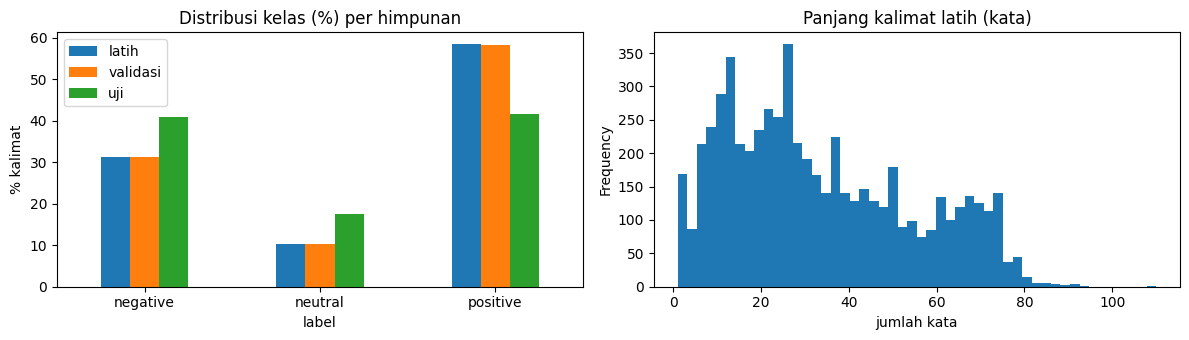

In [9]:
# Subset diambil terstratifikasi dengan DATA_SEED tetap -> SAMA untuk semua run
def ambil_subset(df, n):
    if n is None or n >= len(df):
        return df.reset_index(drop=True)
    sub, _ = train_test_split(df, train_size=n, stratify=df["label"], random_state=DATA_SEED)
    return sub.reset_index(drop=True)

train_full_df = train_df.copy()                 # dipakai baseline TF-IDF "latih penuh" (pembanding Slide 11)
train_df = ambil_subset(train_df, TRAIN_SUBSET)
valid_df = ambil_subset(valid_df, VALID_SUBSET)
test_df  = ambil_subset(test_df, TEST_SUBSET)   # mode penuh: TEST_SUBSET=None -> seluruh 500
y_train = train_df["label"].map(LABEL2ID).to_numpy()
y_valid = valid_df["label"].map(LABEL2ID).to_numpy()
y_test  = test_df["label"].map(LABEL2ID).to_numpy()

# Audit: tidak boleh ada teks yang sama di dua himpunan
OVERLAP = {
    "latih∩validasi": len(set(train_df.text) & set(valid_df.text)),
    "latih∩uji": len(set(train_df.text) & set(test_df.text)),
    "validasi∩uji": len(set(valid_df.text) & set(test_df.text)),
}
assert sum(OVERLAP.values()) == 0, f"Kebocoran data: {OVERLAP}"
print(f"Dipakai -> latih: {len(train_df)} | validasi: {len(valid_df)} | uji: {len(test_df)}")
print("Tumpang-tindih antar-himpunan:", OVERLAP)

dist = pd.DataFrame({
    "latih": train_df["label"].value_counts().reindex(LABELS),
    "validasi": valid_df["label"].value_counts().reindex(LABELS),
    "uji": test_df["label"].value_counts().reindex(LABELS),
})
dist_pct = (dist / dist.sum() * 100).round(1).add_suffix(" (%)")
display(pd.concat([dist, dist_pct], axis=1))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
dist_pct.set_axis(dist.columns, axis=1).plot.bar(ax=axes[0], rot=0, title="Distribusi kelas (%) per himpunan")
axes[0].set_ylabel("% kalimat")
train_df["text"].str.split().str.len().plot.hist(bins=50, ax=axes[1], title="Panjang kalimat latih (kata)")
axes[1].set_xlabel("jumlah kata")
plt.tight_layout(); plt.show()

### 4.3 Pembanding yang sah: baseline TF-IDF & tebakan acak (Slide 11)

Lembar Soal menegaskan "tidak ada angka yang benar"; pembandingnya adalah **baseline TF-IDF notebook sendiri**, **tebakan acak**, dan **simpangan antar-seed**. Baseline dilatih tanpa tuning (hiperparameter tetap) dan dievaluasi pada **uji resmi yang sama** dengan transformer:
- **TF-IDF + regresi logistik (latih penuh)** — padanan acuan Lembar Soal (F1 makro ± 0,73 dengan data latih penuh).
- **TF-IDF + regresi logistik (subset 6.000)** — data latih **sama persis** dengan transformer, pembanding paling adil.
- **Tebakan acak (seragam)** dan **kelas mayoritas**, rata-rata atas seed yang sama.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier

def nilai_baseline(nama, y_pred, n_latih):
    return {"model": nama, "n_latih": n_latih, "accuracy": accuracy_score(y_test, y_pred),
            "f1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0)}

baris_bl = []
for nama, df_l in [("TF-IDF + LogReg (latih penuh)", train_full_df), ("TF-IDF + LogReg (subset latih yang sama)", train_df)]:
    t0 = time.perf_counter()
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                         LogisticRegression(max_iter=2000, C=1.0))          # tanpa tuning
    pipe.fit(df_l["text"], df_l["label"].map(LABEL2ID))
    r = nilai_baseline(nama, pipe.predict(test_df["text"]), len(df_l)); r["train_time_s"] = time.perf_counter() - t0
    baris_bl.append(r)
for strategi_dummy, nama in [("uniform", "Tebakan acak (seragam)"), ("most_frequent", "Kelas mayoritas")]:
    skor = [nilai_baseline(nama, DummyClassifier(strategy=strategi_dummy, random_state=s)
                           .fit(train_df["text"], y_train).predict(test_df["text"]), len(train_df)) for s in SEEDS]
    baris_bl.append({"model": nama, "n_latih": len(train_df),
                     "accuracy": np.mean([s["accuracy"] for s in skor]), "f1_macro": np.mean([s["f1_macro"] for s in skor]),
                     "train_time_s": 0.0})
BASELINE_DF = pd.DataFrame(baris_bl)
BASELINE_DF.to_csv(BASELINE_CSV, index=False)
F1_TFIDF        = float(BASELINE_DF.loc[0, "f1_macro"])     # acuan utama Slide 11 (latih penuh)
F1_TFIDF_SUBSET = float(BASELINE_DF.loc[1, "f1_macro"])
F1_ACAK         = float(BASELINE_DF.loc[2, "f1_macro"])
print(f"Acuan pembanding pada uji resmi: TF-IDF (penuh) F1 = {F1_TFIDF:.4f} | TF-IDF (subset) = {F1_TFIDF_SUBSET:.4f} | acak = {F1_ACAK:.4f}")
BASELINE_DF.round(4)

Acuan pembanding pada uji resmi: TF-IDF (penuh) F1 = 0.6786 | TF-IDF (subset) = 0.6300 | acak = 0.3061


,model,n_latih,accuracy,f1_macro,train_time_s
0,TF-IDF + LogReg (latih penuh),10919,0.7700,0.6786,6.4306
1,TF-IDF + LogReg (subset latih yang sama),6000,0.7380,0.6300,2.9699
2,Tebakan acak (seragam),6000,0.3173,0.3061,0.0000
3,Kelas mayoritas,6000,0.4160,0.1959,0.0000


## 5. Model: Head Replacement & Strategi Fine-Tuning (Soal 3)

*Klausul C.3 — head replacement wajib di semua run, full fine-tuning wajib sebagai baseline, dan minimal satu dari linear probing / partial freezing.*

### 5.1 Tokenisasi per backbone
Setiap backbone memakai tokenizer-nya sendiri. Dicek juga persentase kalimat yang **terpotong** pada `MAX_LENGTH`, sebagai pembenaran nilai `max_length` (klausul C.1).

In [11]:
class DatasetTeks(Dataset):
    def __init__(self, encodings, labels):
        self.enc, self.labels = encodings, labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = int(self.labels[i])
        return item

TOKENIZERS, COLLATORS, DATA, STAT_TOKEN = {}, {}, {}, []
for bk, cfg in BACKBONES.items():
    tok = AutoTokenizer.from_pretrained(cfg["hf"])
    TOKENIZERS[bk] = tok
    COLLATORS[bk] = DataCollatorWithPadding(tok)     # padding dinamis per batch (lebih cepat)
    enc_tr = tok(train_df["text"].tolist(), truncation=True, max_length=MAX_LENGTH)
    enc_va = tok(valid_df["text"].tolist(), truncation=True, max_length=MAX_LENGTH)
    enc_te = tok(test_df["text"].tolist(),  truncation=True, max_length=MAX_LENGTH)
    DATA[bk] = {"train": DatasetTeks(enc_tr, y_train), "valid": DatasetTeks(enc_va, y_valid),
                "test": DatasetTeks(enc_te, y_test)}
    panjang = np.array([len(x) for x in tok(train_df["text"].tolist(), truncation=False)["input_ids"]])
    STAT_TOKEN.append({"backbone": bk, "ukuran_vocab": tok.vocab_size,
                       "rata2_token": panjang.mean().round(1), "p95_token": int(np.percentile(panjang, 95)),
                       "maks_token": int(panjang.max()),
                       f"% terpotong (>{MAX_LENGTH})": round((panjang > MAX_LENGTH).mean() * 100, 2)})

contoh = train_df["text"].iloc[0]
print("Contoh kalimat:", contoh[:120], "...\n")
for bk, tok in TOKENIZERS.items():
    print(f"{bk:12s}:", tok.tokenize(contoh)[:15])
pd.DataFrame(STAT_TOKEN)

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

... (4 outputs left out)

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Contoh kalimat: baik , selain wisata wahana saya juga suka wisata kuliner . sejak saya di bandung kuliner yang paling saya buru adalah s ...

mbert       : ['baik', ',', 'selain', 'wisata', 'wa', '##hana', 'saya', 'juga', 'su', '##ka', 'wisata', 'ku', '##liner', '.', 'sejak']
distilmbert : ['baik', ',', 'selain', 'wisata', 'wa', '##hana', 'saya', 'juga', 'su', '##ka', 'wisata', 'ku', '##liner', '.', 'sejak']
indobert    : ['baik', ',', 'selain', 'wisata', 'wahana', 'saya', 'juga', 'suka', 'wisata', 'kuliner', '.', 'sejak', 'saya', 'di', 'bandung']


,backbone,ukuran_vocab,rata2_token,p95_token,maks_token,% terpotong (>128)
0,mbert,119547,50.7,104,176,0.15
1,distilmbert,119547,50.7,104,176,0.15
2,indobert,30521,38.3,80,132,0.02


### 5.2 Head Replacement (wajib untuk semua run)
`AutoModelForSequenceClassification` memuat **badan (backbone) pretrained**, membuang head pretraining (MLM/NSP), lalu memasang **head klasifikasi baru** berukuran `hidden_size → NUM_LABELS (3)` dengan bobot acak.
Opsi `output_loading_info=True` dipakai untuk **membuktikan** bahwa bobot head memang baru: bobot itu muncul di `missing_keys`, artinya tidak ada di checkpoint pretrained.

In [12]:
def buat_model(hf_name):
    # Muat backbone pretrained + pasang head klasifikasi baru (head replacement)
    model, info = AutoModelForSequenceClassification.from_pretrained(
        hf_name, num_labels=NUM_LABELS, id2label=ID2LABEL, label2id=LABEL2ID,
        ignore_mismatched_sizes=True, output_loading_info=True)
    assert model.config.num_labels == NUM_LABELS
    return model, info

def modul_head(model):
    # Head = semua modul tingkat atas di luar backbone (base_model)
    return {n: m for n, m in model.named_children() if n != model.base_model_prefix and n != "dropout"}

for bk, cfg in BACKBONES.items():
    m, info = buat_model(cfg["hf"])
    print(f"=== {cfg['nama']} ({cfg['hf']}) ===")
    for nama, mod in modul_head(m).items():
        print(f"  head baru -> {nama}: {mod}")
    print(f"  bobot baru (tidak ada di checkpoint): {info['missing_keys']}\n")
    del m
gc.collect()

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

=== mBERT (bert-base-multilingual-cased) ===
  head baru -> classifier: Linear(in_features=768, out_features=3, bias=True)
  bobot baru (tidak ada di checkpoint): {'classifier.weight', 'classifier.bias'}



model.safetensors: reconstructing file:   0%|          |  0.00B /  542MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

=== IndoBERT (indobenchmark/indobert-base-p1) ===
  head baru -> classifier: Linear(in_features=768, out_features=3, bias=True)
  bobot baru (tidak ada di checkpoint): {'classifier.weight', 'classifier.bias'}



1704

### 5.3 Strategi Fine-Tuning: kode pembekuan lapis (freezing)

Sesuai klausul C.3, **tiga** strategi dijalankan supaya perbandingannya *apple-to-apple*: `full` (wajib, baseline), `partial` (partial freezing), dan `probing` (linear probing).

| Strategi | Yang dibekukan | Yang dilatih |
|---|---|---|
| **Full fine-tuning** | tidak ada | semua parameter |
| **Partial freezing** | embedding + **separuh lapis awal** encoder (12 → 6 dibekukan; DistilBERT 6 → 3) | separuh lapis atas + pooler + head |
| **Linear probing** | **seluruh** backbone (embedding, semua lapis, pooler) | hanya head |

Pembekuan dilakukan dengan `param.requires_grad = False`, sehingga optimizer hanya menerima parameter yang `requires_grad=True`.
*Catatan:* pada DistilBERT head klasifikasi berisi **dua modul berurutan** (`pre_classifier` lalu `classifier`), sedangkan pada BERT/IndoBERT hanya satu modul linear (`classifier`). Yang dimaksud "dua modul" di sini bukan dua lapis transformer. Pada probing, pooler BERT ikut dibekukan karena merupakan bagian dari backbone pretrained.

In [13]:
def ambil_bagian_backbone(model):
    # Kembalikan (backbone, embeddings, daftar lapis encoder) secara generik untuk BERT/DistilBERT/XLM-R
    base = getattr(model, model.base_model_prefix)               # .bert / .distilbert / .roberta
    if hasattr(base, "encoder"):                                  # BERT, IndoBERT, XLM-R
        layers = base.encoder.layer
    elif hasattr(base, "transformer"):                            # DistilBERT
        layers = base.transformer.layer
    else:
        raise ValueError(f"Arsitektur tidak dikenali: {type(base)}")
    return base, base.embeddings, layers

def terapkan_strategi(model, strategi):
    base, embeddings, layers = ambil_bagian_backbone(model)
    for p in model.parameters():                                  # mulai dari semua bisa dilatih
        p.requires_grad = True

    if strategi == "full":
        pass                                                      # tidak ada yang dibekukan
    elif strategi == "partial":
        for p in embeddings.parameters():                         # bekukan embedding
            p.requires_grad = False
        n_beku = len(layers) // 2                                 # 12 -> 6, DistilBERT 6 -> 3
        for layer in layers[:n_beku]:                             # bekukan separuh lapis AWAL
            for p in layer.parameters():
                p.requires_grad = False
    elif strategi == "probing":
        for p in base.parameters():                               # bekukan SELURUH backbone
            p.requires_grad = False
    else:
        raise ValueError(strategi)

    for mod in modul_head(model).values():                        # head SELALU dilatih
        for p in mod.parameters():
            p.requires_grad = True

    total = sum(p.numel() for p in model.parameters())
    dilatih = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {"params_total": total, "params_trainable": dilatih,
            "persen_trainable": round(100 * dilatih / total, 3), "n_lapis": len(layers)}

In [14]:
# Verifikasi: jumlah parameter yang dilatih harus berurutan probing < partial < full untuk SETIAP backbone
URUTAN = [s for s in ["probing", "partial", "full"] if s in STRATEGIES]
baris = []
for bk, cfg in BACKBONES.items():
    m, _ = buat_model(cfg["hf"])
    info = {st: terapkan_strategi(m, st) for st in URUTAN}
    dilatih = [info[st]["params_trainable"] for st in URUTAN]
    assert all(a < b for a, b in zip(dilatih, dilatih[1:])), f"Urutan parameter salah untuk {bk}: {dilatih}"
    for st in URUTAN:
        baris.append({"backbone": bk, "strategi": st, "n_lapis": info[st]["n_lapis"],
                      "params_total (juta)": round(info[st]["params_total"] / 1e6, 1),
                      "params_dilatih": info[st]["params_trainable"],
                      "% dilatih": info[st]["persen_trainable"]})
    del m; gc.collect()
print("✅ Urutan parameter dilatih valid: " + " < ".join(URUTAN) + " untuk semua backbone")
TABEL_PARAM = pd.DataFrame(baris)
TABEL_PARAM

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✅ Urutan parameter dilatih valid: probing < partial < full untuk semua backbone


,backbone,strategi,n_lapis,params_total (juta),params_dilatih,% dilatih
0,mbert,probing,12,177.9,2307,0.001
1,mbert,partial,12,177.9,43120131,24.244
2,mbert,full,12,177.9,177855747,100.000
3,distilmbert,probing,6,135.3,592899,0.438
4,distilmbert,partial,6,135.3,21856515,16.151
5,distilmbert,full,6,135.3,135326979,100.000
6,indobert,probing,12,124.4,2307,0.002
7,indobert,partial,12,124.4,43120131,34.650
8,indobert,full,12,124.4,124443651,100.000


## 6. Fungsi Pelatihan & Evaluasi

*Spesifikasi "Metrik per run (otomatis)" + Slide 10 (validasi hanya memilih epoch; uji disentuh sekali per run).*

Untuk setiap run: `set_seed(seed)` → buat model (head baru) → terapkan strategi → latih hingga `EPOCHS` epoch. Di akhir **setiap epoch** model dievaluasi pada **validasi**; bobot dengan **F1 makro validasi tertinggi** disimpan. Setelah pelatihan selesai, bobot terbaik dimuat lalu dievaluasi **satu kali** pada **uji resmi**.

Metrik yang dicatat otomatis: **akurasi, F1 makro, F1 per kelas (pada uji), epoch terbaik & F1 validasi per epoch, waktu latih (tanpa waktu validasi), waktu inferensi (ms/kalimat), parameter total dan yang dilatih, serta memori GPU puncak**.

In [15]:
def sinkron():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

def ke_device(batch):
    return {k: v.to(DEVICE) for k, v in batch.items()}

@torch.no_grad()
def prediksi(model, loader):
    # Prediksi + waktu inferensi (ms/kalimat). Batch pertama dipakai sebagai pemanasan (warm-up).
    model.eval()
    warm = ke_device({k: v for k, v in next(iter(loader)).items() if k != "labels"})
    with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
        model(**warm)
    sinkron(); t0 = time.perf_counter()
    preds, n = [], 0
    for batch in loader:
        inp = ke_device({k: v for k, v in batch.items() if k != "labels"})
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(**inp).logits
        preds.append(logits.argmax(-1).cpu()); n += logits.size(0)
    sinkron()
    return torch.cat(preds).numpy(), (time.perf_counter() - t0) * 1000 / n

def latih_dan_evaluasi(bk, st, seed):
    set_seed(seed)                                         # reproduksibilitas (python, numpy, torch, cuda)
    model, _ = buat_model(BACKBONES[bk]["hf"])             # head replacement
    info_param = terapkan_strategi(model, st)              # freezing sesuai strategi
    model.to(DEVICE)

    g = torch.Generator(); g.manual_seed(seed)             # urutan shuffle ikut seed
    dl_train = DataLoader(DATA[bk]["train"], batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=COLLATORS[bk], generator=g)
    dl_valid = DataLoader(DATA[bk]["valid"], batch_size=EVAL_BATCH_SIZE, shuffle=False, collate_fn=COLLATORS[bk])
    dl_test  = DataLoader(DATA[bk]["test"],  batch_size=EVAL_BATCH_SIZE, shuffle=False, collate_fn=COLLATORS[bk])

    no_decay = ("bias", "LayerNorm.weight", "layer_norm.weight")
    dilatih = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    grup = [{"params": [p for n, p in dilatih if not any(nd in n for nd in no_decay)], "weight_decay": WEIGHT_DECAY},
            {"params": [p for n, p in dilatih if any(nd in n for nd in no_decay)], "weight_decay": 0.0}]
    lr = STRATEGIES[st]["lr"]
    optimizer = torch.optim.AdamW(grup, lr=lr)
    total_step = len(dl_train) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_step), total_step)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    waktu_latih, loss_epoch, f1_valid_epoch = 0.0, [], []
    f1_valid_terbaik, epoch_terbaik, state_terbaik = -1.0, 0, None
    for ep in range(EPOCHS):
        sinkron(); t0 = time.perf_counter()
        model.train(); total_loss, n = 0.0, 0
        for batch in dl_train:
            batch = ke_device(batch)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                loss = model(**batch).loss
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_([p for _, p in dilatih], GRAD_CLIP)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            total_loss += loss.item() * batch["labels"].size(0); n += batch["labels"].size(0)
        sinkron(); waktu_latih += time.perf_counter() - t0          # waktu validasi TIDAK dihitung
        loss_epoch.append(total_loss / n)
        # ---- Validasi: HANYA untuk memilih epoch terbaik (Slide 10) ----
        y_val_pred, _ = prediksi(model, dl_valid)
        f1_v = f1_score(y_valid, y_val_pred, average="macro", zero_division=0)
        f1_valid_epoch.append(f1_v)
        if f1_v > f1_valid_terbaik:
            f1_valid_terbaik, epoch_terbaik = f1_v, ep + 1
            state_terbaik = {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}
    mem_puncak = torch.cuda.max_memory_allocated() / 2**20 if DEVICE.type == "cuda" else float("nan")

    # ---- Uji resmi: disentuh SEKALI, memakai bobot epoch terbaik ----
    model.load_state_dict(state_terbaik)
    y_pred, infer_ms = prediksi(model, dl_test)
    f1_kelas = f1_score(y_test, y_pred, average=None, labels=list(range(NUM_LABELS)), zero_division=0)
    hasil = {
        "kode": KODE, "dataset": DATASET, "mode": MODE, "run_id": f"{bk}|{st}|{seed}",
        "backbone": bk, "backbone_hf": BACKBONES[bk]["hf"], "strategi": st, "seed": seed,
        "lr": lr, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "max_length": MAX_LENGTH,
        "n_train": len(DATA[bk]["train"]), "n_valid": len(DATA[bk]["valid"]), "n_test": len(DATA[bk]["test"]),
        "best_epoch": epoch_terbaik, "f1_valid_best": f1_valid_terbaik,
        "f1_valid_epoch": json.dumps([round(x, 4) for x in f1_valid_epoch]),
        "accuracy": accuracy_score(y_test, y_pred),
        "f1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
        **{f"f1_{lab}": f1_kelas[i] for i, lab in enumerate(LABELS)},
        "train_time_s": waktu_latih, "infer_ms_per_kalimat": infer_ms,
        **info_param, "peak_mem_mb": mem_puncak,
        "loss_epoch": json.dumps([round(x, 4) for x in loss_epoch]),
        "gpu": GPU_NAME, "selesai_pada": datetime.now().isoformat(timespec="seconds"),
    }
    del model, optimizer, scheduler, scaler, state_terbaik
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return hasil, y_pred


## 7. Matriks Eksperimen (Soal 2 & Soal 3)

*Klausul C.2 + C.3 — minimal 3 backbone diuji dengan protokol yang sama persis, tiap kombinasi dijalankan dengan minimal 3 seed, dan minimal satu backbone dicoba dengan SEMUA strategi.*

- Setiap run langsung **ditambahkan ke `hasil_<dataset>_<kode>.csv`**, dan prediksinya disimpan ke `prediksi_<dataset>_<kode>.json`.
- Run yang sudah ada di CSV **dilewati**, jadi aman untuk dilanjutkan setelah sesi terputus.
- Urutan loop: backbone → strategi → seed.
- Skor yang dicetak (`acc`, `F1`) adalah skor **uji resmi** dengan bobot epoch terbaik (`ep*`) yang dipilih lewat validasi.
- Tabel berikut merangkum hasil akhir matriks (kolom `f1_macro`) setelah semua run selesai.

In [16]:
cek_rancangan(tegas=(MODE == "penuh"))   # penjaga: mode penuh DITOLAK bila rancangan belum lengkap; mode uji hanya diperingatkan

def daftar_run():
    for bk in BACKBONES:
        if JALANKAN_BACKBONE and bk not in JALANKAN_BACKBONE:
            continue
        for st in STRATEGIES:
            if JALANKAN_STRATEGI and st not in JALANKAN_STRATEGI:
                continue
            for seed in SEEDS:
                yield bk, st, seed

def muat_hasil():
    return pd.read_csv(HASIL_CSV) if HASIL_CSV.exists() else pd.DataFrame()

def simpan_baris(baris):
    pd.DataFrame([baris]).to_csv(HASIL_CSV, mode="a", header=not HASIL_CSV.exists(), index=False)

PREDIKSI = json.loads(PRED_JSON.read_text()) if PRED_JSON.exists() else {}
selesai = set(muat_hasil().get("run_id", pd.Series(dtype=str)))
antrian = [r for r in daftar_run() if f"{r[0]}|{r[1]}|{r[2]}" not in selesai]
print(f"Total run di matriks: {len(list(daftar_run()))} | sudah selesai: {len(selesai)} | akan dijalankan: {len(antrian)}\n")

t_mulai = time.time()
for i, (bk, st, seed) in enumerate(antrian, 1):
    print(f"[{i}/{len(antrian)}] {bk:12s} | {st:8s} | seed {seed} ...", end=" ", flush=True)
    hasil, y_pred = latih_dan_evaluasi(bk, st, seed)
    simpan_baris(hasil)
    PREDIKSI[hasil["run_id"]] = y_pred.tolist()
    PRED_JSON.write_text(json.dumps(PREDIKSI))
    sisa = (time.time() - t_mulai) / i * (len(antrian) - i)
    print(f"ep*={hasil['best_epoch']} | uji acc={hasil['accuracy']:.4f} | F1={hasil['f1_macro']:.4f} | latih={hasil['train_time_s']:.0f}s "
          f"| infer={hasil['infer_ms_per_kalimat']:.2f} ms/kal | ETA sisa ≈ {sisa/60:.1f} mnt")

print(f"\n✅ Selesai. Semua run tersimpan di {HASIL_CSV}")
hasil_df = muat_hasil()
hasil_df[["run_id", "best_epoch", "f1_valid_best", "accuracy", "f1_macro", "train_time_s", "infer_ms_per_kalimat",
          "params_trainable", "peak_mem_mb"]].round(4)

✅ Rancangan lengkap dan sudah dikonfirmasi.
Total run di matriks: 27 | sudah selesai: 0 | akan dijalankan: 27

[1/27] mbert        | full     | seed 42 ... 

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

ep*=3 | uji acc=0.8300 | F1=0.7910 | latih=137s | infer=1.31 ms/kal | ETA sisa ≈ 64.2 mnt
[2/27] mbert        | full     | seed 123 ... 

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

ep*=3 | uji acc=0.8000 | F1=0.7636 | latih=139s | infer=1.38 ms/kal | ETA sisa ≈ 62.2 mnt
[3/27] mbert        | full     | seed 2024 ... 

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (46 outputs left out)

ep*=3 | uji acc=0.8240 | F1=0.7713 | latih=28s | infer=1.08 ms/kal | ETA sisa ≈ 1.2 mnt
[27/27] indobert     | probing  | seed 2024 ... 

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

ep*=3 | uji acc=0.8340 | F1=0.7860 | latih=28s | infer=1.06 ms/kal | ETA sisa ≈ 0.0 mnt

✅ Selesai. Semua run tersimpan di /content/drive/MyDrive/Hasil_Studio3/hasil_studio3/hasil_smsa_b7e8fed2.csv


,run_id,best_epoch,f1_valid_best,accuracy,f1_macro,train_time_s,infer_ms_per_kalimat,params_trainable,peak_mem_mb
0,mbert|full|42,3,0.8564,0.830,0.7910,137.2291,1.3131,177855747,3912.4858
1,mbert|full|123,3,0.8487,0.800,0.7636,139.4111,1.3789,177855747,3926.7358
2,mbert|full|2024,3,0.8438,0.826,0.7825,139.4836,1.3660,177855747,3911.8755
3,mbert|partial|42,3,0.8243,0.772,0.7322,74.8806,1.3426,43120131,2006.3950
4,mbert|partial|123,3,0.8164,0.770,0.7354,74.9450,1.3848,43120131,1999.4575
5,mbert|partial|2024,3,0.8113,0.768,0.7224,75.2026,1.3463,43120131,2016.8950
6,mbert|probing|42,3,0.6743,0.548,0.4714,36.1461,1.3866,2307,930.9741
7,mbert|probing|123,3,0.6750,0.544,0.4759,36.2478,1.3638,2307,924.2168
8,mbert|probing|2024,2,0.6746,0.552,0.4690,35.6974,1.3480,2307,924.2197
9,distilmbert|full|42,3,0.8309,0.768,0.7166,80.0095,0.7324,135326979,2661.0322


In [17]:
# Rangkuman matriks hasil (F1 makro): satu baris per kombinasi backbone × strategi × seed
try:
    ringkas_bk = (hasil_df.pivot_table(index=["backbone", "backbone_hf"], columns="strategi",
                                       values="f1_macro", aggfunc="mean").round(4))
    ringkas_bk.index = ringkas_bk.index.droplevel(1)
    print("Rata-rata F1 makro per kombinasi (baris = backbone, kolom = strategi):")
    display(ringkas_bk)
except Exception as e:
    print("Ringkasan belum bisa dibuat (hasil belum lengkap):", e)

TAMPIL = [c for c in ["run_id", "backbone", "strategi", "seed", "lr", "best_epoch", "f1_valid_best", "accuracy", "f1_macro",
                      "train_time_s", "infer_ms_per_kalimat", "params_total", "params_trainable",
                      "persen_trainable", "peak_mem_mb"] if c in hasil_df]
print(f"Total baris hasil: {len(hasil_df)}")
hasil_df[TAMPIL].round(5)

Rata-rata F1 makro per kombinasi (baris = backbone, kolom = strategi):


strategi,full,partial,probing
backbone,,,
distilmbert,0.7141,0.6489,0.5028
indobert,0.8688,0.8816,0.7848
mbert,0.7790,0.7300,0.4721


Total baris hasil: 27


,run_id,backbone,strategi,seed,lr,best_epoch,f1_valid_best,accuracy,f1_macro,train_time_s,infer_ms_per_kalimat,params_total,params_trainable,persen_trainable,peak_mem_mb
0,mbert|full|42,mbert,full,42,0.00002,3,0.85636,0.830,0.79099,137.22913,1.31311,177855747,177855747,100.000,3912.48584
1,mbert|full|123,mbert,full,123,0.00002,3,0.84867,0.800,0.76358,139.41109,1.37891,177855747,177855747,100.000,3926.73584
2,mbert|full|2024,mbert,full,2024,0.00002,3,0.84384,0.826,0.78246,139.48365,1.36604,177855747,177855747,100.000,3911.87549
3,mbert|partial|42,mbert,partial,42,0.00003,3,0.82426,0.772,0.73217,74.88058,1.34256,177855747,43120131,24.244,2006.39502
4,mbert|partial|123,mbert,partial,123,0.00003,3,0.81637,0.770,0.73542,74.94498,1.38481,177855747,43120131,24.244,1999.45752
5,mbert|partial|2024,mbert,partial,2024,0.00003,3,0.81130,0.768,0.72244,75.20261,1.34626,177855747,43120131,24.244,2016.89502
6,mbert|probing|42,mbert,probing,42,0.00500,3,0.67435,0.548,0.47136,36.14611,1.38658,177855747,2307,0.001,930.97412
7,mbert|probing|123,mbert,probing,123,0.00500,3,0.67497,0.544,0.47589,36.24777,1.36382,177855747,2307,0.001,924.21680
8,mbert|probing|2024,mbert,probing,2024,0.00500,2,0.67459,0.552,0.46897,35.69740,1.34799,177855747,2307,0.001,924.21973
9,distilmbert|full|42,distilmbert,full,42,0.00002,3,0.83088,0.768,0.71655,80.00948,0.73241,135326979,135326979,100.000,2661.03223


## 8. (Opsional) Menggabungkan Hasil Antar-Anggota

*Penunjang pembagian kerja kelompok (bukan klausul tersendiri). Notebook utama mengerjakan matriks utuh, jadi bagian ini dilewati bila tidak ada pembagian kerja.*

Jika matriks dibagi antar-anggota:
1. Setiap anggota mengunduh `hasil_smsa_<KODE>.csv` dan `prediksi_smsa_<KODE>.json` miliknya.
2. Unggah semua file itu ke folder `hasil_studio3/gabung/` di notebook utama. Nama file boleh diberi akhiran, misalnya `hasil_smsa_<KODE>_anggota2.csv`.
3. Jalankan sel di bawah. Sel ini **menolak** file dengan kode konfigurasi berbeda.

> Catatan: waktu inferensi dari sesi yang berbeda **tidak** boleh dibandingkan langsung. Untuk itu ada bagian 9, yang mengukur ulang waktu inferensi semua backbone **dalam satu sesi**.

In [18]:
GABUNG_DIR = OUTPUT_DIR / "gabung"; GABUNG_DIR.mkdir(exist_ok=True)
csv_lain = sorted(GABUNG_DIR.glob(f"hasil_{DATASET}_*.csv"))
if not csv_lain:
    print("Tidak ada file di folder gabung/ — lewati (wajar jika semua run dikerjakan di notebook ini).")
else:
    semua = [muat_hasil()] + [pd.read_csv(f) for f in csv_lain]
    gabungan = pd.concat([d for d in semua if len(d)], ignore_index=True)
    kode_lain = set(gabungan["kode"]) - {KODE}
    assert not kode_lain, f"⛔ Ada hasil dengan konfigurasi berbeda: {kode_lain}. Samakan konfigurasi!"
    gabungan = gabungan.drop_duplicates(subset="run_id", keep="first")
    gabungan.to_csv(HASIL_CSV, index=False)
    for f in GABUNG_DIR.glob(f"prediksi_{DATASET}_*.json"):
        for k, v in json.loads(f.read_text()).items():
            PREDIKSI.setdefault(k, v)
    PRED_JSON.write_text(json.dumps(PREDIKSI))
    print(f"✅ Digabung: {len(gabungan)} run unik dari {len(csv_lain) + 1} sumber -> {HASIL_CSV.name}")

Tidak ada file di folder gabung/ — lewati (wajar jika semua run dikerjakan di notebook ini).


## 9. Benchmark Waktu Inferensi dalam Satu Sesi

*Klausul "Metrik per run": waktu inferensi (ms/kalimat) hanya dibandingkan dalam satu sesi yang sama.*

Kecepatan inferensi hanya ditentukan oleh **arsitektur** backbone dan tidak bergantung pada strategi maupun bobot hasil latih, karena ketiga strategi menghasilkan arsitektur yang sama. Karena itu, setiap backbone diukur sekali **di sesi yang sama**, dengan dua skenario:
- **Batch 1:** latensi per kalimat, yang relevan untuk pemakaian *real-time*.
- **Batch `EVAL_BATCH_SIZE`:** *throughput*, yang relevan untuk pemrosesan massal.

Setiap pengukuran diulang 3 kali, lalu diambil **median**-nya.

In [19]:
N_LATENSI = min(200, len(test_df))   # jumlah kalimat untuk uji batch-1
ULANG = 3
baris = []
for bk, cfg in BACKBONES.items():
    m, _ = buat_model(cfg["hf"]); m.to(DEVICE)
    sub = torch.utils.data.Subset(DATA[bk]["test"], range(N_LATENSI))
    dl1 = DataLoader(sub, batch_size=1, collate_fn=COLLATORS[bk])
    dlb = DataLoader(DATA[bk]["test"], batch_size=EVAL_BATCH_SIZE, collate_fn=COLLATORS[bk])
    lat = [prediksi(m, dl1)[1] for _ in range(ULANG)]
    thr = [prediksi(m, dlb)[1] for _ in range(ULANG)]
    baris.append({"backbone": bk, "params_total (juta)": round(sum(p.numel() for p in m.parameters()) / 1e6, 1),
                  "latensi_batch1_ms_per_kalimat": float(np.median(lat)),
                  f"throughput_batch{EVAL_BATCH_SIZE}_ms_per_kalimat": float(np.median(thr)),
                  "gpu": GPU_NAME})
    del m; gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
INFER_DF = pd.DataFrame(baris)
INFER_DF.to_csv(INFER_CSV, index=False)
INFER_DF.round(3)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,backbone,params_total (juta),latensi_batch1_ms_per_kalimat,throughput_batch64_ms_per_kalimat,gpu
0,mbert,177.9,18.386,1.416,Tesla T4
1,distilmbert,135.3,18.568,0.775,Tesla T4
2,indobert,124.4,27.702,1.077,Tesla T4


## 10. Rekap Agregat (rata-rata ± simpangan baku antar-seed)

*Klausul "Pelaporan hasil" — rata-rata ± simpangan baku antar-seed, BUKAN cuma nilai terbaik dari satu kali coba.*

Sesuai spesifikasi, yang dilaporkan adalah **rata-rata ± simpangan baku antar-seed** (std sampel, `ddof=1`), **bukan** nilai terbaik dari satu run. Hasilnya disimpan ke `rekap_agregat_<dataset>_<kode>.csv`.

In [20]:
hasil_df = muat_hasil()
assert len(hasil_df), "Belum ada hasil run. Jalankan bagian 7 dulu."
ORDER_BK = [b for b in BACKBONES if b in set(hasil_df["backbone"])]
ORDER_ST = [s for s in STRATEGIES if s in set(hasil_df["strategi"])]

METRIK = ["accuracy", "f1_macro", "f1_negative", "f1_neutral", "f1_positive", "f1_valid_best", "best_epoch",
          "train_time_s", "infer_ms_per_kalimat", "peak_mem_mb"]
agg = hasil_df.groupby(["backbone", "strategi"]).agg(
    n_seed=("seed", "nunique"),
    **{f"{m}_mean": (m, "mean") for m in METRIK},
    **{f"{m}_std": (m, "std") for m in METRIK},
    params_total=("params_total", "first"),
    params_trainable=("params_trainable", "first"),
    persen_trainable=("persen_trainable", "first"),
).reset_index()
agg["backbone"] = pd.Categorical(agg["backbone"], ORDER_BK, ordered=True)
agg["strategi"] = pd.Categorical(agg["strategi"], ORDER_ST, ordered=True)
agg = agg.sort_values(["backbone", "strategi"]).reset_index(drop=True)
agg.insert(0, "kode", KODE)
agg.to_csv(REKAP_CSV, index=False)
print(f"✅ Rekap disimpan: {REKAP_CSV}")

def pm(m, s, k=4):
    return f"{m:.{k}f} ± {0 if pd.isna(s) else s:.{k}f}"

TABEL_UTAMA = pd.DataFrame({
    "Backbone": agg["backbone"].map(lambda b: BACKBONES[b]["nama"]),
    "Strategi": agg["strategi"].map(lambda s: STRATEGIES[s]["nama"]),
    "n seed": agg["n_seed"],
    "Akurasi": [pm(m, s) for m, s in zip(agg["accuracy_mean"], agg["accuracy_std"])],
    "F1 makro (uji)": [pm(m, s) for m, s in zip(agg["f1_macro_mean"], agg["f1_macro_std"])],
    "Δ vs TF-IDF (poin)": ((agg["f1_macro_mean"] - F1_TFIDF) * 100).round(2),
    "Epoch terbaik (rata2)": agg["best_epoch_mean"].round(2),
    "Waktu latih (s)": [pm(m, s, 1) for m, s in zip(agg["train_time_s_mean"], agg["train_time_s_std"])],
    "Inferensi (ms/kal)": [pm(m, s, 3) for m, s in zip(agg["infer_ms_per_kalimat_mean"], agg["infer_ms_per_kalimat_std"])],
    "Param total (jt)": (agg["params_total"] / 1e6).round(1),
    "Param dilatih": agg["params_trainable"].map("{:,}".format),
    "% dilatih": agg["persen_trainable"].round(2),
    "Memori puncak (MB)": agg["peak_mem_mb_mean"].round(0),
})
if (agg["n_seed"] < 3).any() and MODE == "penuh":
    print("⚠️ Ada kombinasi dengan < 3 seed — lengkapi run sebelum melaporkan!")
TABEL_UTAMA

✅ Rekap disimpan: /content/drive/MyDrive/Hasil_Studio3/hasil_studio3/rekap_agregat_smsa_b7e8fed2.csv


,Backbone,Strategi,n seed,Akurasi,F1 makro (uji),Δ vs TF-IDF (poin),Epoch terbaik (rata2),Waktu latih (s),Inferensi (ms/kal),Param total (jt),Param dilatih,% dilatih,Memori puncak (MB)
0,mBERT,Full fine-tuning,3,0.8187 ± 0.0163,0.7790 ± 0.0140,10.04,3.00,138.7 ± 1.3,1.353 ± 0.035,177.9,"177,855,747",100.00,3917.0
1,mBERT,Partial freezing (emb + 50% lapis awal),3,0.7700 ± 0.0020,0.7300 ± 0.0068,5.14,3.00,75.0 ± 0.2,1.358 ± 0.023,177.9,"43,120,131",24.24,2008.0
2,mBERT,Linear probing (hanya head),3,0.5480 ± 0.0040,0.4721 ± 0.0035,-20.65,2.67,36.0 ± 0.3,1.366 ± 0.019,177.9,"2,307",0.00,926.0
3,DistilmBERT,Full fine-tuning,3,0.7620 ± 0.0087,0.7141 ± 0.0054,3.55,3.00,80.2 ± 0.2,0.723 ± 0.025,135.3,"135,326,979",100.00,2666.0
4,DistilmBERT,Partial freezing (emb + 50% lapis awal),3,0.6993 ± 0.0190,0.6489 ± 0.0169,-2.97,3.00,37.0 ± 0.3,0.691 ± 0.008,135.3,"21,856,515",16.15,1233.0
5,DistilmBERT,Linear probing (hanya head),3,0.5747 ± 0.0212,0.5028 ± 0.0292,-17.58,2.67,18.8 ± 0.2,0.703 ± 0.042,135.3,"592,899",0.44,758.0
6,IndoBERT,Full fine-tuning,3,0.9020 ± 0.0080,0.8688 ± 0.0097,19.02,2.33,105.3 ± 0.4,1.074 ± 0.012,124.4,"124,443,651",100.00,3307.0
7,IndoBERT,Partial freezing (emb + 50% lapis awal),3,0.9120 ± 0.0072,0.8816 ± 0.0141,20.31,2.33,60.6 ± 0.2,1.072 ± 0.007,124.4,"43,120,131",34.65,1797.0
8,IndoBERT,Linear probing (hanya head),3,0.8340 ± 0.0100,0.7848 ± 0.0129,10.62,3.00,28.3 ± 0.2,1.071 ± 0.010,124.4,"2,307",0.00,689.0


In [21]:
# Tabel pivot F1 makro (mean ± std): backbone × strategi
pivot = agg.pivot(index="backbone", columns="strategi", values="f1_macro_mean").loc[ORDER_BK, ORDER_ST]
pivot_std = agg.pivot(index="backbone", columns="strategi", values="f1_macro_std").loc[ORDER_BK, ORDER_ST]
pivot_txt = pivot.round(4).astype(str) + " ± " + pivot_std.fillna(0).round(4).astype(str)
pivot_txt.index = [BACKBONES[b]["nama"] for b in pivot_txt.index]
print("F1 makro (mean ± std antar-seed)")
pivot_txt

F1 makro (mean ± std antar-seed)


strategi,full,partial,probing
mBERT,0.779 ± 0.014,0.73 ± 0.0068,0.4721 ± 0.0035
DistilmBERT,0.7141 ± 0.0054,0.6489 ± 0.0169,0.5028 ± 0.0292
IndoBERT,0.8688 ± 0.0097,0.8816 ± 0.0141,0.7848 ± 0.0129


## 11. Visualisasi

Grafik yang dihasilkan: (a) performa per backbone × strategi, (b) trade-off performa vs biaya komputasi, (c) sebaran antar-seed + kurva loss, (d) confusion matrix konfigurasi terbaik.

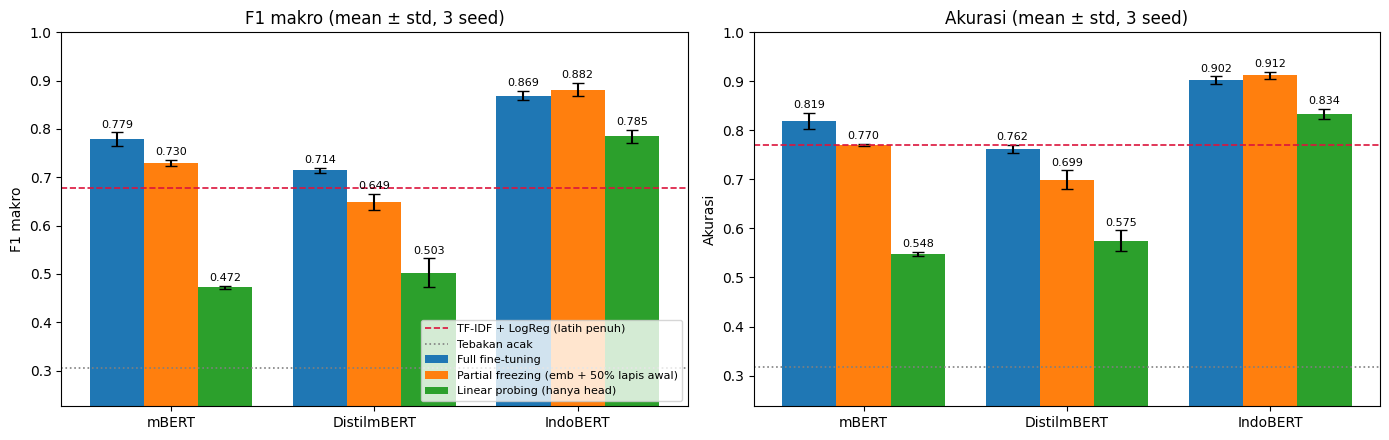

In [22]:
WARNA = {"full": "#1f77b4", "partial": "#ff7f0e", "probing": "#2ca02c"}
nama_bk = [BACKBONES[b]["nama"] for b in ORDER_BK]
x = np.arange(len(ORDER_BK)); w = 0.8 / len(ORDER_ST)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for j, (metrik, judul) in enumerate([("f1_macro", "F1 makro"), ("accuracy", "Akurasi")]):
    ax = axes[j]
    for i, st in enumerate(ORDER_ST):
        d = agg[agg["strategi"] == st].set_index("backbone").loc[ORDER_BK]
        b = ax.bar(x + (i - (len(ORDER_ST) - 1) / 2) * w, d[f"{metrik}_mean"], w,
                   yerr=d[f"{metrik}_std"].fillna(0), capsize=4, label=STRATEGIES[st]["nama"],
                   color=WARNA.get(st))
        ax.bar_label(b, fmt="%.3f", fontsize=8, padding=2)
    ax.set_xticks(x, nama_bk); ax.set_ylabel(judul); ax.set_title(f"{judul} (mean ± std, {len(SEEDS)} seed)")
    acuan = {"f1_macro": (F1_TFIDF, F1_ACAK), "accuracy": tuple(BASELINE_DF.loc[[0, 2], "accuracy"])}[metrik]
    ax.axhline(acuan[0], color="crimson", ls="--", lw=1.2, label="TF-IDF + LogReg (latih penuh)")
    ax.axhline(acuan[1], color="gray", ls=":", lw=1.2, label="Tebakan acak")
    ax.set_ylim(max(0, min(agg[f"{metrik}_mean"].min(), acuan[1]) - 0.08), 1.0)
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / f"grafik_performa_{KODE}.png", dpi=150); plt.show()

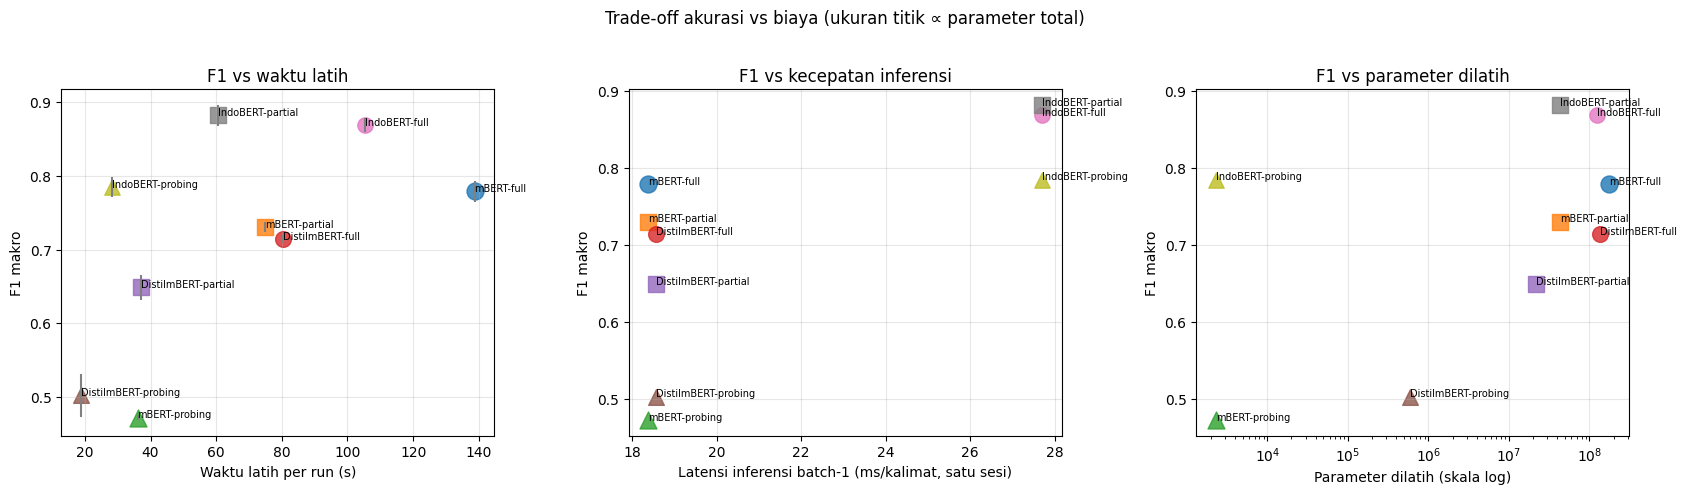

In [23]:
# Trade-off: performa vs biaya komputasi
MARKER = {"full": "o", "partial": "s", "probing": "^"}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
lat = INFER_DF.set_index("backbone")["latensi_batch1_ms_per_kalimat"] if "INFER_DF" in globals() else None
for _, r in agg.iterrows():
    lab = f"{BACKBONES[r['backbone']]['nama']}-{r['strategi']}"
    kw = dict(marker=MARKER.get(r["strategi"], "o"), s=60 + r["params_total"] / 2e6, alpha=.8)
    axes[0].errorbar(r["train_time_s_mean"], r["f1_macro_mean"], yerr=r["f1_macro_std"], fmt="none", ecolor="gray")
    axes[0].scatter(r["train_time_s_mean"], r["f1_macro_mean"], **kw); axes[0].annotate(lab, (r["train_time_s_mean"], r["f1_macro_mean"]), fontsize=7)
    xi = lat[r["backbone"]] if lat is not None else r["infer_ms_per_kalimat_mean"]
    axes[1].scatter(xi, r["f1_macro_mean"], **kw); axes[1].annotate(lab, (xi, r["f1_macro_mean"]), fontsize=7)
    axes[2].scatter(r["params_trainable"], r["f1_macro_mean"], **kw); axes[2].annotate(lab, (r["params_trainable"], r["f1_macro_mean"]), fontsize=7)
axes[0].set(xlabel="Waktu latih per run (s)", ylabel="F1 makro", title="F1 vs waktu latih")
axes[1].set(xlabel="Latensi inferensi batch-1 (ms/kalimat, satu sesi)", ylabel="F1 makro", title="F1 vs kecepatan inferensi")
axes[2].set(xlabel="Parameter dilatih (skala log)", ylabel="F1 makro", title="F1 vs parameter dilatih", xscale="log")
for ax in axes: ax.grid(alpha=.3)
plt.suptitle("Trade-off akurasi vs biaya (ukuran titik ∝ parameter total)", y=1.02)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / f"grafik_tradeoff_{KODE}.png", dpi=150, bbox_inches="tight"); plt.show()

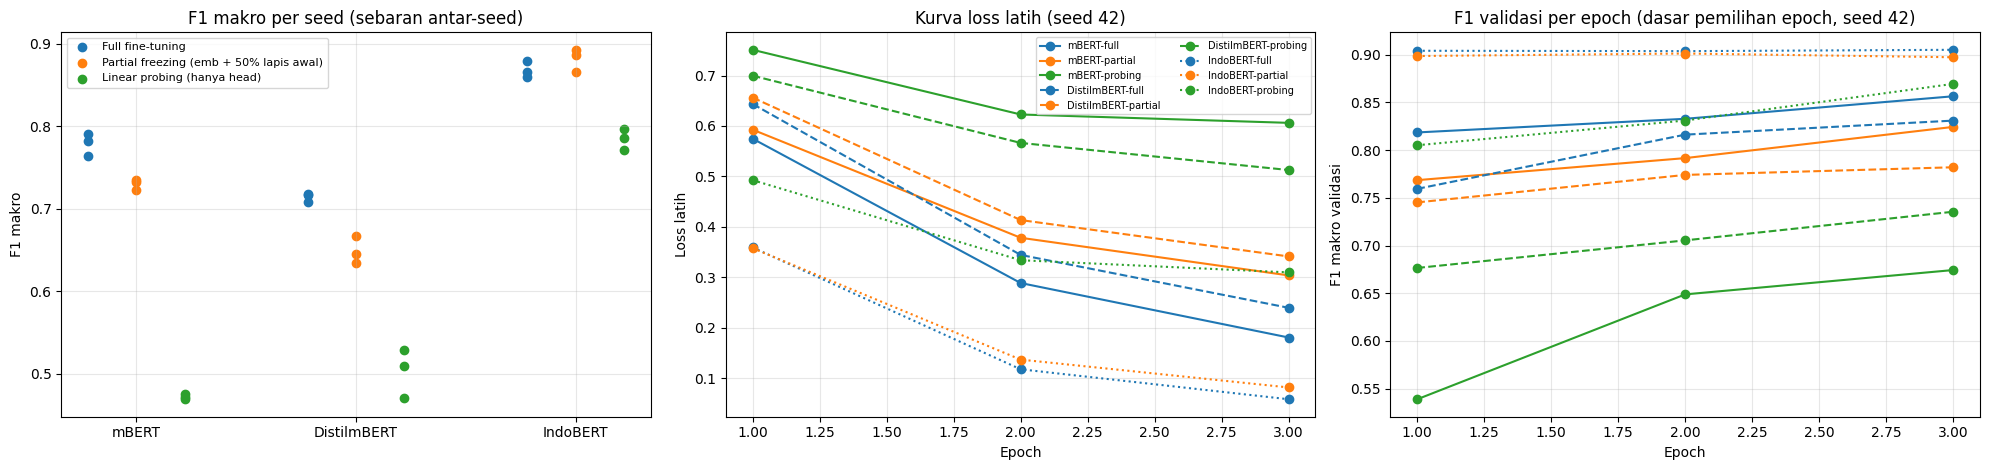

In [24]:
# Variasi antar-seed + kurva loss latih
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
for i, st in enumerate(ORDER_ST):
    for k, bk in enumerate(ORDER_BK):
        v = hasil_df[(hasil_df["backbone"] == bk) & (hasil_df["strategi"] == st)]["f1_macro"]
        axes[0].scatter(np.full(len(v), k + (i - 1) * 0.22), v, color=WARNA.get(st),
                        label=STRATEGIES[st]["nama"] if k == 0 else None)
axes[0].set_xticks(range(len(ORDER_BK)), nama_bk); axes[0].set_ylabel("F1 makro")
axes[0].set_title("F1 makro per seed (sebaran antar-seed)"); axes[0].legend(fontsize=8); axes[0].grid(alpha=.3)

for _, r in hasil_df[hasil_df["seed"] == SEEDS[0]].iterrows():
    le = json.loads(r["loss_epoch"])
    axes[1].plot(range(1, len(le) + 1), le, marker="o", color=WARNA.get(r["strategi"]),
                 ls={0: "-", 1: "--", 2: ":", 3: "-."}[ORDER_BK.index(r["backbone"]) % 4],
                 label=f"{BACKBONES[r['backbone']]['nama']}-{r['strategi']}")
axes[1].set(xlabel="Epoch", ylabel="Loss latih", title=f"Kurva loss latih (seed {SEEDS[0]})")
axes[1].legend(fontsize=7, ncol=2); axes[1].grid(alpha=.3)
for _, r in hasil_df[hasil_df["seed"] == SEEDS[0]].iterrows():
    fv = json.loads(r["f1_valid_epoch"])
    axes[2].plot(range(1, len(fv) + 1), fv, marker="o", color=WARNA.get(r["strategi"]),
                 ls={0: "-", 1: "--", 2: ":", 3: "-."}[ORDER_BK.index(r["backbone"]) % 4])
axes[2].set(xlabel="Epoch", ylabel="F1 makro validasi", title=f"F1 validasi per epoch (dasar pemilihan epoch, seed {SEEDS[0]})")
axes[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / f"grafik_seed_loss_{KODE}.png", dpi=150); plt.show()

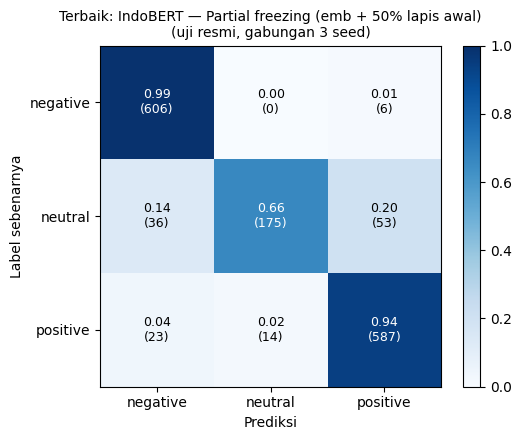

Classification report (indobert|partial|42):

              precision    recall  f1-score   support

    negative     0.9091    0.9804    0.9434       204
     neutral     0.9630    0.5909    0.7324        88
    positive     0.8850    0.9615    0.9217       208

    accuracy                         0.9040       500
   macro avg     0.9190    0.8443    0.8658       500
weighted avg     0.9085    0.9040    0.8972       500



In [25]:
# Confusion matrix konfigurasi terbaik (F1 makro rata-rata tertinggi), dijumlahkan atas semua seed
terbaik = agg.sort_values("f1_macro_mean", ascending=False).iloc[0]
bk_t, st_t = terbaik["backbone"], terbaik["strategi"]
cm = np.zeros((NUM_LABELS, NUM_LABELS), dtype=int)
for seed in SEEDS:
    rid = f"{bk_t}|{st_t}|{seed}"
    if rid in PREDIKSI:
        cm += confusion_matrix(y_test, PREDIKSI[rid], labels=list(range(NUM_LABELS)))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(NUM_LABELS):
    for j in range(NUM_LABELS):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center",
                color="white" if cm_norm[i, j] > .5 else "black", fontsize=9)
ax.set_xticks(range(NUM_LABELS), LABELS); ax.set_yticks(range(NUM_LABELS), LABELS)
ax.set_xlabel("Prediksi"); ax.set_ylabel("Label sebenarnya")
ax.set_title(f"Terbaik: {BACKBONES[bk_t]['nama']} — {STRATEGIES[st_t]['nama']}\n(uji resmi, gabungan {len(SEEDS)} seed)", fontsize=10)
plt.colorbar(im, fraction=.046); plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"grafik_confusion_{KODE}.png", dpi=150); plt.show()

rid0 = f"{bk_t}|{st_t}|{SEEDS[0]}"
if rid0 in PREDIKSI:
    print(f"Classification report ({rid0}):\n")
    print(classification_report(y_test, PREDIKSI[rid0], target_names=LABELS, digits=4))

## 12. Pengujian Hipotesis H1–H3

*Klausul C.1 — hipotesis ditulis di Rancangan (bagian 3) dan diuji di sini berbasis bukti eksperimen.*

Hipotesis dinilai dari **selisih rata-rata** dan dibandingkan dengan **variasi antar-seed**. Sebagai pelengkap ditampilkan *Welch t-test*. Dengan hanya 3 seed per kelompok, daya ujinya rendah, jadi nilai p ini hanya **indikatif**, bukan bukti kuat.
- Status **"didukung"** diberikan jika arah selisih sesuai hipotesis **dan** selisihnya lebih besar dari gabungan simpangan baku (std₁ + std₂).
- Status **"cenderung/lemah"** diberikan jika arahnya sesuai tetapi selisihnya masih dalam rentang variasi seed.

In [26]:
try:
    from scipy.stats import ttest_ind
except ImportError:
    ttest_ind = None

def nilai(bk, st, m="f1_macro"):
    return hasil_df[(hasil_df["backbone"] == bk) & (hasil_df["strategi"] == st)][m].to_numpy()

def bandingkan(a, b, nama_a, nama_b, arah="lebih_besar", m="f1_macro"):
    if len(a) == 0 or len(b) == 0:
        return f"   (data {nama_a}/{nama_b} belum tersedia)"
    d = a.mean() - b.mean()
    sa, sb = (a.std(ddof=1) if len(a) > 1 else 0), (b.std(ddof=1) if len(b) > 1 else 0)
    sesuai = d > 0 if arah == "lebih_besar" else d < 0
    status = ("✅ didukung" if sesuai and abs(d) > sa + sb else
              "🟡 cenderung (dalam rentang variasi seed)" if sesuai else "❌ tidak didukung")
    p = f" | Welch p = {ttest_ind(a, b, equal_var=False).pvalue:.3f}" if ttest_ind and len(a) > 1 and len(b) > 1 else ""
    return (f"   {m}: {nama_a} {a.mean():.4f}±{sa:.4f} vs {nama_b} {b.mean():.4f}±{sb:.4f} "
            f"-> selisih {d:+.4f}{p}\n   Status: {status}")

def rata(bk, st, m):
    v = nilai(bk, st, m); return v.mean() if len(v) else float("nan")

print("H1 — IndoBERT > mBERT (full fine-tuning)")
print(bandingkan(nilai("indobert", "full"), nilai("mbert", "full"), "IndoBERT", "mBERT"))
if PAKAI_XLMR and "xlmr" in ORDER_BK:
    print("   (pembanding tambahan) IndoBERT vs XLM-R:")
    print(bandingkan(nilai("indobert", "full"), nilai("xlmr", "full"), "IndoBERT", "XLM-R"))

print("\nH2 — DistilmBERT lebih efisien dari mBERT dengan penurunan F1 kecil (full fine-tuning)")
print(bandingkan(nilai("distilmbert", "full", "train_time_s"), nilai("mbert", "full", "train_time_s"),
                 "DistilmBERT", "mBERT", arah="lebih_kecil", m="train_time_s"))
print(bandingkan(nilai("distilmbert", "full"), nilai("mbert", "full"), "DistilmBERT", "mBERT", arah="lebih_kecil"))
f1_d, f1_m = rata("distilmbert", "full", "f1_macro"), rata("mbert", "full", "f1_macro")
print(f"   Penurunan F1 makro: {(f1_m - f1_d) * 100:+.2f} poin (hipotesis: <= 3 poin)")
if "INFER_DF" in globals():
    L = INFER_DF.set_index("backbone")["latensi_batch1_ms_per_kalimat"]
    print(f"   Latensi batch-1 (satu sesi): DistilmBERT {L['distilmbert']:.2f} ms vs mBERT {L['mbert']:.2f} ms "
          f"-> {(1 - L['distilmbert'] / L['mbert']) * 100:.1f}% lebih cepat")
    print(f"   Waktu latih: {(1 - rata('distilmbert','full','train_time_s') / rata('mbert','full','train_time_s')) * 100:.1f}% lebih cepat")

print("\nH3 — full >= partial > probing (per backbone)")
for bk in ORDER_BK:
    urut = sorted(ORDER_ST, key=lambda s: -rata(bk, s, "f1_macro"))
    print(f" • {BACKBONES[bk]['nama']}: urutan aktual = {' > '.join(urut)}")
    if {"full", "partial"} <= set(ORDER_ST):
        print(f"   full - partial = {(rata(bk,'full','f1_macro') - rata(bk,'partial','f1_macro')) * 100:+.2f} poin (hipotesis: <= 2 poin)")
    if {"partial", "probing"} <= set(ORDER_ST):
        print(bandingkan(nilai(bk, "partial"), nilai(bk, "probing"), "partial", "probing"))

H1 — IndoBERT > mBERT (full fine-tuning)
   f1_macro: IndoBERT 0.8688±0.0097 vs mBERT 0.7790±0.0140 -> selisih +0.0898 | Welch p = 0.001
   Status: ✅ didukung

H2 — DistilmBERT lebih efisien dari mBERT dengan penurunan F1 kecil (full fine-tuning)
   train_time_s: DistilmBERT 80.2230±0.2427 vs mBERT 138.7080±1.2812 -> selisih -58.4849 | Welch p = 0.000
   Status: ✅ didukung
   f1_macro: DistilmBERT 0.7141±0.0054 vs mBERT 0.7790±0.0140 -> selisih -0.0649 | Welch p = 0.008
   Status: ✅ didukung
   Penurunan F1 makro: +6.49 poin (hipotesis: <= 3 poin)
   Latensi batch-1 (satu sesi): DistilmBERT 18.57 ms vs mBERT 18.39 ms -> -1.0% lebih cepat
   Waktu latih: 42.2% lebih cepat

H3 — full >= partial > probing (per backbone)
 • mBERT: urutan aktual = full > partial > probing
   full - partial = +4.90 poin (hipotesis: <= 2 poin)
   f1_macro: partial 0.7300±0.0068 vs probing 0.4721±0.0035 -> selisih +0.2579 | Welch p = 0.000
   Status: ✅ didukung
 • DistilmBERT: urutan aktual = full > partial > 

### 12.1 Tabel bukti untuk 3 Pertanyaan Riset Wajib (Q1–Q3)

Kriteria yang dipakai sudah ditetapkan di Rancangan (bagian 3.6) **sebelum** eksperimen:
- **Q1:** F1 makro ± SD, waktu latih, waktu inferensi (latensi batch-1 dan throughput batch-64, satu sesi), jumlah parameter. Kolom *Pareto* = tidak ada konfigurasi lain yang sekaligus lebih akurat **dan** lebih cepat inferensinya.
- **Q2:** selisih dengan full FT **bermakna** bila |Δ| > SD₁ + SD₂; *kompetitif* bila tidak bermakna atau ≤ 2 poin, dan tetap di atas TF-IDF.
- **Q3:** syarat minimum F1 > TF-IDF; skor = 0,5·F1 + 0,25·kecepatan inferensi + 0,25·hemat waktu latih (min–max).

In [27]:
# ---------- Q1: trade-off akurasi vs efisiensi per backbone ----------
LAT = INFER_DF.set_index("backbone")
thr_col = [c for c in INFER_DF.columns if c.startswith("throughput")][0]
q1 = agg[agg["strategi"] == "full"].copy()
Q1_TABEL = pd.DataFrame({
    "Backbone": q1["backbone"].map(lambda b: BACKBONES[b]["nama"]),
    "F1 makro uji (full FT)": [pm(m, s) for m, s in zip(q1["f1_macro_mean"], q1["f1_macro_std"])],
    "Akurasi uji": [pm(m, s) for m, s in zip(q1["accuracy_mean"], q1["accuracy_std"])],
    "Waktu latih (s)": [pm(m, s, 1) for m, s in zip(q1["train_time_s_mean"], q1["train_time_s_std"])],
    "Latensi batch-1 (ms/kal)": q1["backbone"].map(LAT["latensi_batch1_ms_per_kalimat"]).round(2).values,
    "Throughput batch-64 (ms/kal)": q1["backbone"].map(LAT[thr_col]).round(3).values,
    "Parameter total (jt)": (q1["params_total"] / 1e6).round(1).values,
    "Memori puncak (MB)": q1["peak_mem_mb_mean"].round(0).values,
})
print("Q1 — Backbone pada full fine-tuning (protokol identik, uji resmi 500 kalimat)")
display(Q1_TABEL)

# Pareto (semua 9 konfigurasi): F1 makro tinggi & latensi batch-1 rendah
pts = agg.assign(lat=agg["backbone"].map(LAT["latensi_batch1_ms_per_kalimat"]).astype(float))
def didominasi(r):
    return any((o.f1_macro_mean >= r.f1_macro_mean) and (o.lat <= r.lat) and
               ((o.f1_macro_mean > r.f1_macro_mean) or (o.lat < r.lat)) for o in pts.itertuples())
pts["Pareto (F1 vs latensi)"] = ["✅" if not didominasi(r) else "" for r in pts.itertuples()]
print("Konfigurasi pada batas Pareto F1-vs-latensi:")
display(pts.loc[pts["Pareto (F1 vs latensi)"] == "✅", ["backbone", "strategi", "f1_macro_mean", "f1_macro_std", "lat", "train_time_s_mean"]].round(4))

Q1 — Backbone pada full fine-tuning (protokol identik, uji resmi 500 kalimat)


,Backbone,F1 makro uji (full FT),Akurasi uji,Waktu latih (s),Latensi batch-1 (ms/kal),Throughput batch-64 (ms/kal),Parameter total (jt),Memori puncak (MB)
0,mBERT,0.7790 ± 0.0140,0.8187 ± 0.0163,138.7 ± 1.3,18.386072,1.416045,177.9,3917.0
3,DistilmBERT,0.7141 ± 0.0054,0.7620 ± 0.0087,80.2 ± 0.2,18.567810,0.775418,135.3,2666.0
6,IndoBERT,0.8688 ± 0.0097,0.9020 ± 0.0080,105.3 ± 0.4,27.702355,1.077337,124.4,3307.0


Konfigurasi pada batas Pareto F1-vs-latensi:


,backbone,strategi,f1_macro_mean,f1_macro_std,lat,train_time_s_mean
0,mbert,full,0.7790,0.0140,18.3861,138.7080
7,indobert,partial,0.8816,0.0141,27.7024,60.5834


In [28]:
# ---------- Q2: apakah partial/probing kompetitif vs full FT? selisih dibandingkan simpangan antar-seed ----------
baris = []
for bk in ORDER_BK:
    f = nilai(bk, "full")
    for st in [s for s in ORDER_ST if s != "full"]:
        v = nilai(bk, st)
        d = v.mean() - f.mean(); sd = f.std(ddof=1) + v.std(ddof=1)
        p = ttest_ind(v, f, equal_var=False).pvalue if ttest_ind else float("nan")
        bermakna = abs(d) > sd
        kompetitif = ((not bermakna) or abs(d) <= 0.02) and v.mean() > F1_TFIDF
        hemat = 1 - rata(bk, st, "train_time_s") / rata(bk, "full", "train_time_s")
        baris.append({"Backbone": BACKBONES[bk]["nama"], "Strategi": st,
                      "F1 strategi": pm(v.mean(), v.std(ddof=1)), "F1 full": pm(f.mean(), f.std(ddof=1)),
                      "Δ F1 (poin)": round(d * 100, 2), "SD₁+SD₂ (poin)": round(sd * 100, 2),
                      "|Δ| / (SD₁+SD₂)": round(abs(d) / sd, 1) if sd > 0 else float("inf"),
                      "Welch p": round(p, 4),
                      "Selisih bermakna?": "ya" if bermakna else "belum beda",
                      "> TF-IDF?": "ya" if v.mean() > F1_TFIDF else "TIDAK",
                      "Hemat waktu latih": f"{hemat*100:.1f}%",
                      "Kompetitif?": "✅ ya" if kompetitif else "❌ tidak"})
Q2_TABEL = pd.DataFrame(baris)
print(f"Q2 — Strategi hemat vs full FT (acuan TF-IDF latih penuh = {F1_TFIDF:.4f})")
Q2_TABEL

Q2 — Strategi hemat vs full FT (acuan TF-IDF latih penuh = 0.6786)


,Backbone,Strategi,F1 strategi,F1 full,Δ F1 (poin),SD₁+SD₂ (poin),|Δ| / (SD₁+SD₂),Welch p,Selisih bermakna?,> TF-IDF?,Hemat waktu latih,Kompetitif?
0,mBERT,partial,0.7300 ± 0.0068,0.7790 ± 0.0140,-4.90,2.08,2.4,0.0135,ya,ya,45.9%,❌ tidak
1,mBERT,probing,0.4721 ± 0.0035,0.7790 ± 0.0140,-30.69,1.75,17.5,0.0004,ya,TIDAK,74.0%,❌ tidak
2,DistilmBERT,partial,0.6489 ± 0.0169,0.7141 ± 0.0054,-6.52,2.22,2.9,0.0147,ya,TIDAK,53.9%,❌ tidak
3,DistilmBERT,probing,0.5028 ± 0.0292,0.7141 ± 0.0054,-21.14,3.46,6.1,0.0051,ya,TIDAK,76.6%,❌ tidak
4,IndoBERT,partial,0.8816 ± 0.0141,0.8688 ± 0.0097,1.29,2.38,0.5,0.2707,belum beda,ya,42.4%,✅ ya
5,IndoBERT,probing,0.7848 ± 0.0129,0.8688 ± 0.0097,-8.40,2.26,3.7,0.0012,ya,ya,73.1%,❌ tidak


In [29]:
# ---------- Q3: skor gabungan sesuai kriteria yang ditetapkan di Rancangan ----------
def minmax(x, besar_lebih_baik=True):
    x = np.asarray(x, dtype=float); r = (x - x.min()) / (x.max() - x.min()) if x.max() > x.min() else np.ones_like(x)
    return r if besar_lebih_baik else 1 - r

q3 = pts.copy()
q3["lolos_syarat (F1 > TF-IDF)"] = q3["f1_macro_mean"] > F1_TFIDF
q3["s_F1"] = minmax(q3["f1_macro_mean"])
q3["s_inferensi"] = minmax(q3["lat"], besar_lebih_baik=False)
q3["s_latih"] = minmax(q3["train_time_s_mean"], besar_lebih_baik=False)
q3["skor"] = 0.5 * q3["s_F1"] + 0.25 * q3["s_inferensi"] + 0.25 * q3["s_latih"]
q3.loc[~q3["lolos_syarat (F1 > TF-IDF)"], "skor"] = np.nan          # gugur syarat minimum
Q3_TABEL = (q3.assign(Backbone=q3["backbone"].map(lambda b: BACKBONES[b]["nama"]),
                      F1=[pm(m, s) for m, s in zip(q3["f1_macro_mean"], q3["f1_macro_std"])])
              .sort_values("skor", ascending=False, na_position="last")
              [["Backbone", "strategi", "F1", "lat", "train_time_s_mean", "params_trainable",
                "lolos_syarat (F1 > TF-IDF)", "s_F1", "s_inferensi", "s_latih", "skor"]]
              .rename(columns={"lat": "latensi b1 (ms)", "train_time_s_mean": "waktu latih (s)"})
              .round(3).reset_index(drop=True))
Q3_TABEL.index += 1
print("Q3 — Peringkat kombinasi (bobot: 0,5 F1 + 0,25 inferensi + 0,25 waktu latih; NaN = gugur syarat F1 > TF-IDF)")
display(Q3_TABEL)
# Uji sensitivitas bobot: apakah juara berubah bila akurasi lebih/kurang diutamakan?
for wf in [0.33, 0.5, 0.7]:
    sk = wf * q3["s_F1"] + (1 - wf) / 2 * (q3["s_inferensi"] + q3["s_latih"])
    sk = sk.where(q3["lolos_syarat (F1 > TF-IDF)"])   # syarat minimum F1 > TF-IDF tetap berlaku
    j = q3.loc[sk.idxmax()]
    print(f"   bobot F1 = {wf:.2f} -> juara: {BACKBONES[j['backbone']]['nama']} + {j['strategi']}")

Q3 — Peringkat kombinasi (bobot: 0,5 F1 + 0,25 inferensi + 0,25 waktu latih; NaN = gugur syarat F1 > TF-IDF)


,Backbone,strategi,F1,latensi b1 (ms),waktu latih (s),params_trainable,lolos_syarat (F1 > TF-IDF),s_F1,s_inferensi,s_latih,skor
1,mBERT,partial,0.7300 ± 0.0068,18.386,75.009,43120131,True,0.630,1.00,0.531,0.698
2,IndoBERT,partial,0.8816 ± 0.0141,27.702,60.583,43120131,True,1.000,0.00,0.652,0.663
3,DistilmBERT,full,0.7141 ± 0.0054,18.568,80.223,135326979,True,0.591,0.98,0.488,0.663
4,mBERT,full,0.7790 ± 0.0140,18.386,138.708,177855747,True,0.749,1.00,0.000,0.625
5,IndoBERT,probing,0.7848 ± 0.0129,27.702,28.334,2307,True,0.764,0.00,0.920,0.612
6,IndoBERT,full,0.8688 ± 0.0097,27.702,105.263,124443651,True,0.969,0.00,0.279,0.554
7,mBERT,probing,0.4721 ± 0.0035,18.386,36.030,2307,False,0.000,1.00,0.856,NaN
8,DistilmBERT,partial,0.6489 ± 0.0169,18.568,37.006,21856515,False,0.432,0.98,0.848,NaN
9,DistilmBERT,probing,0.5028 ± 0.0292,18.568,18.801,592899,False,0.075,0.98,1.000,NaN


   bobot F1 = 0.33 -> juara: mBERT + partial
   bobot F1 = 0.50 -> juara: mBERT + partial
   bobot F1 = 0.70 -> juara: IndoBERT + partial


## 13. Analisis, Rekomendasi, dan Kesimpulan

*Bagian ini diisi dari hasil 27 run berkode konfigurasi `b7e8fed2` (bagian 7–12). Semua skor adalah skor **uji resmi SmSA (500 kalimat)** dengan bobot dari epoch terbaik pilihan validasi, dilaporkan sebagai **rata-rata ± simpangan baku antar 3 seed** (42, 123, 2024). **F1 makro** menjadi metrik utama karena kelas timpang dan sebaran uji berbeda dari latih (netral 10,4% di latih vs 17,6% di uji).*

**Aturan pembacaan (ditetapkan di Rancangan 3.6):** selisih disebut **bermakna** bila |Δ| > SD₁ + SD₂ (gabungan simpangan antar-seed). Selisih yang lebih kecil ditulis *belum bisa dibedakan dari variasi seed*. Welch t-test hanya pelengkap karena n = 3 per kelompok.

### 13.1 Ringkasan hasil & pembanding yang sah (Slide 11)

Tabel 13.1 — F1 makro pada uji resmi (rata-rata ± SD antar-seed)

| Backbone ↓ / Strategi → | Full fine-tuning | Partial freezing | Linear probing |
|---|:-:|:-:|:-:|
| mBERT | 0.7790 ± 0.0140 | 0.7300 ± 0.0068 | 0.4721 ± 0.0035 |
| DistilmBERT | 0.7141 ± 0.0054 | 0.6489 ± 0.0169 | 0.5028 ± 0.0292 |
| **IndoBERT** | 0.8688 ± 0.0097 | **0.8816 ± 0.0141** | 0.7848 ± 0.0129 |
| *Pembanding:* TF-IDF + LogReg (latih penuh 10.919) | 0.6786 | | |
| *Pembanding:* TF-IDF + LogReg (subset 6.000 yang sama) | 0.6300 | | |
| *Pembanding:* tebakan acak / kelas mayoritas | 0.3061 / 0.1959 | | |

**Pemeriksaan kewajaran (Slide 11):**
- **Tidak ada indikasi kebocoran.** F1 tertinggi per run 0.8928 (< 0,97), dan audit tumpang-tindih latih/validasi/uji = 0 (bagian 4).
- **Tidak ada run yang gagal belajar.** Run terendah (mBERT probing, 0.4690) masih jauh di atas tebakan acak (0.3061). Loss latih turun di setiap run.
- **Full fine-tuning ketiga backbone mengalahkan baseline TF-IDF** (+10,04 poin mBERT, +3,55 DistilmBERT, +19,02 IndoBERT).
- **Tiga konfigurasi berada di bawah TF-IDF:** mBERT probing, DistilmBERT probing, dan DistilmBERT partial. Slide 11 menyebut ini wajar untuk probing, dengan saran memeriksa learning rate. LR probing sudah di batas atas rentang (5e-3), dan loss probing mBERT nyaris mendatar di 0,60–0,63 pada epoch 2–3. Jadi penyebabnya bukan LR yang kekecilan, melainkan representasi beku yang kurang terpisah secara linear (lihat 13.3).
- **Catatan baseline:** TF-IDF kami (0.6786) sedikit di bawah angka acuan Lembar Soal (± 0,73). Pengaturan vektorisasinya (n-gram 1–2, tanpa tuning) mungkin berbeda dari acuan. Karena dievaluasi pada 500 kalimat uji yang sama, baseline ini tetap pembanding yang sah.

**Pergeseran sebaran validasi → uji.** Sebaran validasi sama dengan latih (netral 10,4%), sedangkan uji tidak. Akibatnya F1 uji lebih rendah daripada F1 validasi di semua konfigurasi. Penurunannya paling kecil pada IndoBERT (full: 0.9059 → 0.8688, −3,7 poin) dan paling besar pada backbone multibahasa (mBERT full −7,1; DistilmBERT full −10,9; mBERT probing −20,3). Artinya **IndoBERT bukan hanya paling akurat, tetapi juga paling tahan terhadap pergeseran sebaran.**

### 13.2 Q1 — Backbone mana yang memberi trade-off akurasi-vs-efisiensi terbaik?

Tabel 13.2 — Perbandingan backbone pada full fine-tuning (protokol identik)

| Backbone | F1 makro (± SD) | Akurasi | Waktu latih/run (s) | Inferensi per run (ms/kal, batch-64) | Parameter total | Memori puncak |
|---|:-:|:-:|:-:|:-:|:-:|:-:|
| mBERT | 0.7790 ± 0.0140 | 0.8187 | 138,7 ± 1,3 | 1,353 ± 0,035 | 177,9 jt | 3.917 MB |
| DistilmBERT | 0.7141 ± 0.0054 | 0.7620 | 80,2 ± 0,2 | **0,723 ± 0,025** | 135,3 jt | **2.666 MB** |
| **IndoBERT** | **0.8688 ± 0.0097** | **0.9020** | 105,3 ± 0,4 | 1,074 ± 0,012 | **124,4 jt** | 3.307 MB |

**Jawaban: IndoBERT (`indobenchmark/indobert-base-p1`).**
1. **IndoBERT mengalahkan mBERT di semua sumbu sekaligus.** F1 makro +8,98 poin (3,8× gabungan SD; Welch p = 0.001), waktu latih −24,1%, inferensi −20,6% (1,074 vs 1,353 ms/kalimat), parameter −30,1%, dan memori −15,6%. Jadi mBERT **terdominasi** dan tidak punya alasan untuk dipilih.
2. **Keunggulan efisiensi IndoBERT datang dari tokenisasi, bukan arsitektur.** Keduanya sama-sama 12 lapis dengan hidden 768. Kosakata Indonesia IndoBERT membuat kalimat lebih pendek (38,3 vs 50,7 token rata-rata; *wahana*, *suka*, *kuliner* menjadi satu token, sedangkan mBERT memecahnya `wa ##hana`, `su ##ka`, `ku ##liner`). Lebih sedikit token berarti lebih sedikit komputasi per kalimat, dan embedding kosakata yang lebih kecil membuat jumlah parameternya paling sedikit.
3. **DistilmBERT adalah satu-satunya alternatif bila kecepatan menjadi syarat mutlak.** Inferensinya 32,7% lebih cepat daripada IndoBERT (0,723 vs 1,074 ms/kalimat) dan latihnya 23,8% lebih cepat (80,2 vs 105,3 s). Harganya F1 −15,47 poin, dan hanya +3,55 poin di atas baseline TF-IDF. Untuk analisis sentimen, kompromi sebesar itu sulit dibenarkan.
4. **Catatan pengukuran latensi batch-1 (bagian 9).** Benchmark batch-1 sesi ini memberi mBERT 18,39 ms, DistilmBERT 18,57 ms, dan IndoBERT 27,70 ms. Angka ini **tidak konsisten** dengan arsitektur: DistilmBERT hanya 6 lapis tetapi tercatat sama lambat dengan mBERT, dan IndoBERT (arsitektur sama, token lebih sedikit) tercatat 50% lebih lambat. Pada batch-1, GPU didominasi *overhead* peluncuran kernel/Python, dan angka ini hanya satu pengukuran (median 3 ulangan) per backbone. Sebaliknya, ms/kalimat per run (batch-64) berasal dari **9 pengukuran per backbone** dengan SD ≤ 0,03 ms dan urutannya konsisten dengan arsitektur (DistilmBERT < IndoBERT < mBERT), sama dengan *throughput* batch-64 di bagian 9 (0,775 < 1,077 < 1,416). Karena itu **kesimpulan kecepatan inferensi memakai ms/kalimat batch-64**, dan angka batch-1 dicatat sebagai keterbatasan.

### 13.3 Q2 — Apakah strategi hemat komputasi cukup kompetitif dibanding full fine-tuning?

Tabel 13.3 — Selisih F1 makro terhadap full FT dibandingkan simpangan antar-seed

| Backbone | Strategi | Δ F1 vs full | SD₁+SD₂ | \|Δ\|/(SD₁+SD₂) | Bermakna? | > TF-IDF? | Hemat waktu latih | Hemat memori | Kompetitif? |
|---|---|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| mBERT | partial | −4,90 | 2,08 | 2,4 | ya | ya | 45,9% | 48,7% | ❌ |
| mBERT | probing | −30,69 | 1,75 | 17,5 | ya | **tidak** | 74,0% | 76,4% | ❌ |
| DistilmBERT | partial | −6,52 | 2,22 | 2,9 | ya | **tidak** | 53,9% | 53,8% | ❌ |
| DistilmBERT | probing | −21,14 | 3,46 | 6,1 | ya | **tidak** | 76,6% | 71,6% | ❌ |
| **IndoBERT** | **partial** | **+1,29** | 2,38 | 0,5 | **belum beda** | ya | **42,4%** | **45,7%** | ✅ |
| IndoBERT | probing | −8,40 | 2,26 | 3,7 | ya | ya (+10,6) | 73,1% | 79,2% | ❌ |

**Jawaban: hanya partial freezing pada IndoBERT yang kompetitif. Linear probing tidak kompetitif di backbone mana pun.**
1. **IndoBERT + partial freezing setara dengan full FT.** F1-nya 0.8816 ± 0.0141 vs 0.8688 ± 0.0097. Selisih +1,29 poin hanya 0,5× gabungan SD (Welch p = 0.27), jadi **belum bisa dibedakan dari variasi seed** dan tidak boleh diklaim "lebih baik". Dengan performa setara, waktu latihnya 42,4% lebih hemat (60,6 vs 105,3 s), memori puncak 45,7% lebih kecil (1.797 vs 3.307 MB), dan parameter yang dilatih hanya 34,7%.
2. **Dugaan mengapa partial tidak kalah pada IndoBERT:** full FT IndoBERT sudah mencapai F1 validasi ± 0,90 sejak epoch 1, dengan loss latih turun ke 0,05–0,06 di epoch 3. Ini tanda model mulai menghafal data latih yang sebarannya berbeda dari uji. Membekukan embedding dan separuh lapis awal berperan seperti regularisasi (loss akhir 0,08–0,09), sehingga generalisasinya ke uji tidak berkurang.
3. **Pada backbone multibahasa, partial freezing turun bermakna** (mBERT −4,90; DistilmBERT −6,52 poin, keduanya > 2 kali gabungan SD), dan DistilmBERT partial bahkan jatuh di bawah TF-IDF. Kemungkinan penyebabnya, kedua backbone ini memang butuh adaptasi lapis bawah untuk Bahasa Indonesia. F1 validasinya juga masih naik di epoch 3, jadi anggaran 3 epoch terlalu pendek bagi mereka.
4. **Linear probing selalu turun bermakna** (−8,40 sampai −30,69 poin). Probing IndoBERT masih layak sebagai opsi sangat murah (0.7848; 28,3 s; 689 MB; +10,6 poin di atas TF-IDF), tetapi probing mBERT dan DistilmBERT di bawah TF-IDF. Kualitas representasi beku sangat ditentukan kecocokan bahasa pretraining: F1 netral mBERT probing hanya 0.2504, berbanding 0.6205 pada IndoBERT probing.
5. **Pembekuan tidak mempercepat inferensi.** Dalam satu backbone, ms/kalimat praktis sama di ketiga strategi (IndoBERT 1,072–1,074; mBERT 1,353–1,366; DistilmBERT 0,691–0,723), karena arsitektur saat prediksi identik. Penghematan hanya terjadi pada **waktu latih dan memori**.

### 13.4 Q3 — Kombinasi apa yang direkomendasikan, dan mengapa?

**Kriteria (ditetapkan di Rancangan 3.6 sebelum eksperimen):** (1) syarat minimum F1 makro > baseline TF-IDF (0.6786); (2) skor = 0,5 × F1 + 0,25 × kecepatan inferensi + 0,25 × hemat waktu latih (min–max 0–1); (3) bila skor hampir sama, pilih yang F1-nya tidak berbeda bermakna dari terbaik dan parameternya lebih sedikit.

**Hasil perhitungan sesuai kode (bagian 12.1), dilaporkan apa adanya.** Dengan kecepatan inferensi diambil dari benchmark **batch-1**, peringkat teratas adalah mBERT + partial (0,698), lalu IndoBERT + partial (0,663) dan DistilmBERT + full (0,663). Peringkat ini sepenuhnya didorong komponen inferensi: IndoBERT mendapat skor inferensi 0 karena angka batch-1 27,70 ms yang tidak konsisten (lihat 13.2 butir 4). Juaranya juga berganti saat bobot diubah (0,33 dan 0,5 → mBERT partial; 0,7 → IndoBERT partial). Dua hal ini menandakan hasilnya tidak stabil.

**Koreksi:** dengan ms/kalimat per run (batch-64, 9 pengukuran per backbone) sebagai ukuran kecepatan inferensi, hasilnya stabil:

| Bobot F1 | Peringkat 1 | Peringkat 2 | Peringkat 3 |
|:-:|---|---|---|
| 0,33 | IndoBERT + probing (0,706) | **IndoBERT + partial (0,694)** | DistilmBERT + full (0,677) |
| **0,50 (kriteria)** | **IndoBERT + partial (0,772)** | IndoBERT + probing (0,721) | IndoBERT + full (0,662) |
| 0,70 | **IndoBERT + partial (0,863)** | IndoBERT + full (0,785) | IndoBERT + probing (0,738) |

Pada bobot 0,33, IndoBERT + probing unggul tipis (selisih skor 0,012). Namun F1-nya 9,68 poin di bawah IndoBERT + partial, jauh di atas variasi seed, sehingga kriteria (3) tetap memilih partial.

**Rekomendasi utama: IndoBERT + partial freezing** (bekukan embedding + 6 lapis awal, LR 3e-5).
- **Akurasi:** F1 makro tertinggi 0.8816 ± 0.0141 (akurasi 0.9120), setara dengan full FT dan +20,3 poin di atas TF-IDF.
- **Anggaran komputasi:** 60,6 s latih per run dan 1,8 GB memori puncak, sekitar 42–46% lebih hemat daripada full FT. Muat di GPU kecil.
- **Kecepatan inferensi (terukur):** 1,072 ms/kalimat (batch-64), lebih cepat daripada mBERT (1,358) dan hanya kalah dari DistilmBERT yang F1-nya 16,8 poin lebih rendah.
- **Keterjelasan:** keunggulannya bisa ditelusuri ke bukti terukur, yaitu kecocokan bahasa (token per kalimat lebih sedikit, F1 tertinggi di semua kelas), dan setiap selisih yang diklaim sudah dibandingkan dengan simpangan antar-seed.

**Rekomendasi per skenario:**

| Skenario | Pilihan | Alasan |
|---|---|---|
| Umum / seimbang (direkomendasikan) | **IndoBERT + partial** | F1 tertinggi, setara full FT, biaya latih & memori hampir separuh |
| GPU sangat terbatas / latih sesering mungkin | IndoBERT + probing | 0.7848, 28,3 s, 689 MB; masih +10,6 poin di atas TF-IDF |
| Throughput inferensi mutlak diutamakan | DistilmBERT + full | 0,723 ms/kalimat (tercepat), tetapi F1 hanya 0.7141 (+3,6 poin dari TF-IDF) |
| Tidak disarankan | mBERT (strategi apa pun) | Terdominasi IndoBERT pada F1, waktu latih, inferensi, parameter, dan memori |

### 13.5 Pengujian hipotesis (ringkas)

| Hipotesis | Hasil | Status |
|---|---|---|
| H1: IndoBERT > mBERT (full FT) | +8,98 poin, 3,8× gabungan SD, p = 0.001 | ✅ didukung |
| H2: DistilmBERT lebih cepat, penurunan F1 ≤ 3 poin | Latih −42,2%, inferensi −46,6%, **tetapi** F1 turun 6,49 poin (bermakna, p = 0.008) | 🟡 didukung sebagian: efisiensi ya, besaran penurunan F1 tidak |
| H3: full ≥ partial > probing; partial ≤ 2 poin dari full | mBERT & DistilmBERT: urutan benar, tetapi selisih full–partial 4,90 & 6,52 poin. IndoBERT: partial setara full (+1,29, belum beda). Probing terendah di semua backbone | 🟡 didukung sebagian: urutan & probing terendah ya; "partial ≤ 2 poin dari full" hanya berlaku pada IndoBERT |

### 13.6 Kesimpulan

1. **Kecocokan bahasa pretraining adalah faktor terbesar.** IndoBERT, model dengan parameter paling sedikit (124,4 jt), mengalahkan mBERT (177,9 jt) sebesar +8,98 poin F1 makro, sekaligus lebih cepat dilatih dan diinferensi, serta paling tahan terhadap pergeseran sebaran uji.
2. **Strategi hemat hanya kompetitif bila backbone-nya cocok.** Partial freezing pada IndoBERT setara dengan full FT dengan biaya latih dan memori hampir separuh. Pada backbone multibahasa, partial dan probing turun bermakna, dan beberapa jatuh di bawah TF-IDF.
3. **Pembekuan lapis menghemat biaya pelatihan, bukan biaya prediksi.** Untuk mempercepat inferensi, yang perlu diganti adalah arsitekturnya (DistilmBERT 32,7% lebih cepat dari IndoBERT), dengan konsekuensi akurasi yang besar.
4. **Kelas netral adalah sumber kesalahan utama.** Pada konfigurasi terbaik, F1 netral 0.7714 vs negatif 0.9491 dan positif 0.9244. Pada run `indobert|partial|42`, recall netral hanya 0.5909: banyak kalimat netral uji (17,6%, hampir dua kali proporsi latih) diprediksi sebagai kelas lain. Sasaran perbaikan berikutnya adalah penanganan ketimpangan kelas (bobot kelas atau penambahan data netral).
5. **Rekomendasi akhir: IndoBERT + partial freezing**, dengan IndoBERT + probing sebagai opsi anggaran minimum.

### 13.7 Keterbatasan

- **Anggaran 3 epoch menguntungkan IndoBERT.** Semua run full/partial mBERT dan DistilmBERT memilih epoch 3 dengan F1 validasi yang masih naik, sehingga skor keduanya kemungkinan *underestimate*. Epoch dikunci sama demi keadilan protokol.
- **Validasi tidak mewakili sebaran uji** (netral 10,4% vs 17,6%), sehingga epoch pilihan validasi belum tentu optimal untuk uji. Sesuai Slide 10, uji tidak boleh dipakai untuk memilih apa pun.
- **Benchmark latensi batch-1 tidak konsisten dengan arsitektur** (13.2 butir 4). Kesimpulan kecepatan memakai ms/kalimat batch-64 per run. Skor Q3 versi kode (batch-1) dan versi koreksi (batch-64) sama-sama dilaporkan secara transparan.
- Hanya 3 seed (daya uji statistik rendah) dan LR tidak dituning per backbone. Sebagian selisih antar-backbone bisa berasal dari kecocokan LR, walau protokolnya sama untuk semua.
- Baseline TF-IDF (0.6786) sedikit di bawah acuan Lembar Soal (± 0,73) karena pengaturan vektorisasi yang mungkin berbeda.
- XLM-R (opsional) tidak dijalankan. Waktu latih dan inferensi hanya berlaku untuk GPU Tesla T4 dalam satu sesi Colab, dan determinisme GPU tidak dijamin 100%.

## 14. Kepatuhan Spesifikasi & Berkas yang Dikumpulkan

*Klausul "Ciri-ciri Soal 1/2/3 Sudah Beres" dan "Yang Perlu Dikumpulkan". Sel berikut memeriksa kepatuhan terhadap spesifikasi secara otomatis (khususnya bagian yang baru bisa dinilai setelah ada hasil run), lalu mengemas semua berkas hasil.*

In [30]:
# ============ GATE STATIS (bagian 2/2) + kepatuhan berbasis HASIL RUN ============
hasil_df = muat_hasil()
print(f"=== KEPATUHAN SPESIFIKASI (mode {MODE}) {('— berkas uji jalan' if MODE == 'uji' else '— berkas resmi')} ===")
if hasil_df.empty:
    print("⚠️  Belum ada hasil run. Jalankan bagian 7 dulu, lalu jalankan ulang sel ini.")
else:
    per_sel = hasil_df.groupby(["backbone", "strategi"])["seed"].nunique()
    cek = {
        "Soal 1: rancangan lengkap & dikonfirmasi": RANCANGAN_DIKONFIRMASI and all(str(v).strip() for v in RANCANGAN.values()),
        "Soal 2: >= 3 backbone diuji": hasil_df["backbone"].nunique() >= 3,
        "Soal 2: BERT, DistilBERT, IndoBERT ada": {"mbert", "distilmbert", "indobert"} <= set(hasil_df["backbone"]),
        "Soal 2: tiap kombinasi >= 3 seed": bool(len(per_sel)) and per_sel.min() >= 3,
        "Soal 2: tabel memuat akurasi, F1, waktu latih, inferensi, parameter": all(
            c in hasil_df for c in ["accuracy", "f1_macro", "train_time_s", "infer_ms_per_kalimat", "params_total"]),
        "Soal 3: full fine-tuning dijalankan": "full" in set(hasil_df["strategi"]),
        "Soal 3: probing/partial dijalankan": bool({"probing", "partial"} & set(hasil_df["strategi"])),
        "Soal 3: >=1 backbone dengan SEMUA strategi": any(
            set(hasil_df[hasil_df["backbone"] == b]["strategi"]) >= set(STRATEGIES) for b in BACKBONES),
        "Soal 3: LR berbeda per strategi": hasil_df.groupby("strategi")["lr"].first().nunique() == hasil_df["strategi"].nunique(),
        "Hal teknis: berkas hasil & rekap dibuat otomatis": HASIL_CSV.exists() and REKAP_CSV.exists(),
        "Hal teknis: inferensi diukur dalam satu sesi": INFER_CSV.exists(),
        "Mode penuh (bukan uji jalan)": MODE == "penuh",
        "Slide 10: data latih 3.000-6.000": hasil_df["n_train"].between(3000, 6000).all(),
        "Slide 10: validasi >= 500 (hanya untuk memilih epoch)": (hasil_df["n_valid"] >= 500).all(),
        "Slide 10: uji = seluruh 500 uji resmi": (hasil_df["n_test"] == 500).all(),
        "Slide 10: tidak ada tumpang-tindih latih/validasi/uji": sum(OVERLAP.values()) == 0,
        "Slide 11: tidak ada F1 > 0,97 (indikasi kebocoran)": hasil_df["f1_macro"].max() <= 0.97,
        "Slide 11: semua run jauh di atas tebakan acak": hasil_df["f1_macro"].min() > F1_ACAK + 0.1,
        "Slide 11: full FT setiap backbone di atas baseline TF-IDF": all(
            rata(b, "full", "f1_macro") > F1_TFIDF for b in ORDER_BK),
        "Slide 9: tabel bukti Q1-Q3 tersedia": all(k in globals() for k in ["Q1_TABEL", "Q2_TABEL", "Q3_TABEL"]),
    }
    for k, v in cek.items():
        print(("✅" if v else "❌"), k)
    di_bawah = [f"{b}|{s}" for b in ORDER_BK for s in ORDER_ST if rata(b, s, "f1_macro") <= F1_TFIDF]
    if di_bawah:
        print(f"ℹ️  Konfigurasi di bawah TF-IDF ({F1_TFIDF:.4f}): {di_bawah} — Slide 11: wajar untuk probing; LR probing sudah di batas atas rentang (5e-3).")
    if MODE == "uji":
        print("ℹ️  Ini berkas uji jalan (UJI_JALAN=True). Untuk laporan resmi: set UJI_JALAN=False, RANCANGAN_DIKONFIRMASI=True, lalu Run all.")

import zipfile
BERKAS_KODE = sorted(f for f in OUTPUT_DIR.glob(f"*{KODE}{SUFIKS}*") if f.is_file() and f.suffix != ".zip")
arsip = OUTPUT_DIR.parent / f"studio3_{DATASET}_{KODE}{SUFIKS}.zip"
with zipfile.ZipFile(arsip, "w", zipfile.ZIP_DEFLATED) as z:      # hanya berkas konfigurasi INI (tidak tercampur kode lain)
    for f in BERKAS_KODE:
        z.write(f, f.name)
print(f"\n📦 Semua berkas dikemas: {arsip}")
print("Isi arsip:")
for f in BERKAS_KODE:
    print(f"   - {f.name}")

# ============ Rekap berkas yang wajib dikumpulkan (spesifikasi, bagian "Yang Perlu Dikumpulkan") ============
print("\n=== Yang dikumpulkan ke portal e-learning ===")
print("1. Link notebook Colab/Kaggle (akses: Anyone with the link can view).")
print("2. PDF notebook yang sudah dijalankan penuh (berisi kode, output, dan grafik).")
print("   Nama berkas: STUDIO3_Kelompok15_MuhammadFadhilahAkbar_MuhammadFajriFirdaus.pdf")
print(f"3. Berkas hasil: {HASIL_CSV.name} dan {REKAP_CSV.name} (+ {BASELINE_CSV.name}, arsip zip bila diperlukan).")
print("4. Slide (maksimal 15) + laporan singkat 3-4 halaman: rancangan, hasil, analisis, jawaban 3 Pertanyaan Riset Wajib.")

=== KEPATUHAN SPESIFIKASI (mode penuh) — berkas resmi ===
✅ Soal 1: rancangan lengkap & dikonfirmasi
✅ Soal 2: >= 3 backbone diuji
✅ Soal 2: BERT, DistilBERT, IndoBERT ada
✅ Soal 2: tiap kombinasi >= 3 seed
✅ Soal 2: tabel memuat akurasi, F1, waktu latih, inferensi, parameter
✅ Soal 3: full fine-tuning dijalankan
✅ Soal 3: probing/partial dijalankan
✅ Soal 3: >=1 backbone dengan SEMUA strategi
✅ Soal 3: LR berbeda per strategi
✅ Hal teknis: berkas hasil & rekap dibuat otomatis
✅ Hal teknis: inferensi diukur dalam satu sesi
✅ Mode penuh (bukan uji jalan)
✅ Slide 10: data latih 3.000-6.000
✅ Slide 10: validasi >= 500 (hanya untuk memilih epoch)
✅ Slide 10: uji = seluruh 500 uji resmi
✅ Slide 10: tidak ada tumpang-tindih latih/validasi/uji
✅ Slide 11: tidak ada F1 > 0,97 (indikasi kebocoran)
✅ Slide 11: semua run jauh di atas tebakan acak
✅ Slide 11: full FT setiap backbone di atas baseline TF-IDF
✅ Slide 9: tabel bukti Q1-Q3 tersedia
ℹ️  Konfigurasi di bawah TF-IDF (0.6786): ['mbert|prob

In [31]:
# ====== SIMPAN HASIL KE GOOGLE DRIVE (khusus Google Colab) ======
# Di Colab, OUTPUT_DIR sudah berada di Google Drive sejak bagian 2, jadi setiap run langsung tersimpan.
# Sel ini hanya menyalin bila Drive gagal di-mount di awal (OUTPUT_DIR masih lokal).
import shutil
from pathlib import Path

if DI_DRIVE:
    print(f"✅ Hasil sudah tersimpan langsung di Google Drive: {OUTPUT_DIR}")
    for f in BERKAS_KODE:
        print("   -", f.name)
else:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_DIR = Path("/content/drive/MyDrive/Hasil_Studio3")
        tujuan = DRIVE_DIR / OUTPUT_DIR.name
        DRIVE_DIR.mkdir(parents=True, exist_ok=True)
        if tujuan.exists() and tujuan.resolve() != OUTPUT_DIR.resolve():
            shutil.rmtree(tujuan)                      # salinan lama diganti yang terbaru
        shutil.copytree(OUTPUT_DIR, tujuan)
        print(f"✅ Hasil disalin ke Google Drive: {tujuan}")
    except ImportError:
        print("Bukan di Colab: langkah Google Drive dilewati (di Kaggle pakai panel Output).")
    except Exception as e:
        print("⚠️ Gagal menyimpan ke Google Drive:", e)


✅ Hasil sudah tersimpan langsung di Google Drive: /content/drive/MyDrive/Hasil_Studio3/hasil_studio3
   - baseline_smsa_b7e8fed2.csv
   - grafik_confusion_b7e8fed2.png
   - grafik_performa_b7e8fed2.png
   - grafik_seed_loss_b7e8fed2.png
   - grafik_tradeoff_b7e8fed2.png
   - hasil_smsa_b7e8fed2.csv
   - inferensi_sesi_tunggal_smsa_b7e8fed2.csv
   - konfigurasi_smsa_b7e8fed2.json
   - prediksi_smsa_b7e8fed2.json
   - rancangan_smsa_b7e8fed2.json
   - rekap_agregat_smsa_b7e8fed2.csv


In [32]:
# ====== UNDUH HASIL OTOMATIS (Colab) / ambil dari panel Output (Kaggle) ======
# Arsip zip dari bagian 14 hanya berisi berkas konfigurasi ini (KODE yang sama), jadi tidak tercampur hasil lama.
print(f"📦 Arsip hasil: {arsip}")
try:
    from google.colab import files                     # khusus Google Colab
    for f in [HASIL_CSV, REKAP_CSV, Path(arsip)]:
        files.download(str(f))
    print("\n⬇️  Unduhan dikirim: hasil CSV, rekap agregat, dan arsip zip.")
except ImportError:
    print(f"\nBukan di Colab: berkas ada di {OUTPUT_DIR.resolve()} (Kaggle: panel Output).")

📦 Arsip hasil: /content/drive/MyDrive/Hasil_Studio3/studio3_smsa_b7e8fed2.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


⬇️  Unduhan dikirim: hasil CSV, rekap agregat, dan arsip zip.
